# AR tuning experiments — a two-by-two comparison

Sections 1–4 contain one experiment for each combination of starting direction and initial-step rule. Section 5 compares their completed results against one common reference. All four variants use the same Jones-sampled AR(3) models and innovation paths, with one path per model. [Shared runners](../ar_tools/tuning.py).

| Starting direction | Absolute initial step $\gamma_0=s$ | Normalized initial step $\gamma_0=s/L$ |
| --- | --- | --- |
| Independent random direction per process | **Section 1** | **Section 2** |
| $e_1=(1,0,0,0)$ | **Section 3** | **Section 4** |

**Selection uses only achieved empirical width.** On each path, every configuration within `epsilon_win_tolerance` (default $10^{-8}$) of the best achieved width receives +1. Configurations with the highest total count are selected; all tied leaders are retained. Sections 1–4 each use their own grid as the reference (72 configurations by default), while the final comparison uses all four grids together (288 configurations by default). [Counting implementation](../ar_tools/tuning.py), `summarize_configuration_wins`.

Each matrix cell shows black **W** (width co-winner count) and green **MAE** (mean coefficient MAE for that configuration). MAE is a diagnostic annotation and does not affect selection, background colors or red winner boxes. One start is used and stationarity-triggered restarts are disabled. [Counting implementation](../ar_tools/tuning.py), [optimizer](../ar_tools/descent.py).

Green outlines mark every configuration tied for the lowest **unrounded mean coefficient MAE**: within the individual matrix in Sections 1–4, and **across all four grids together** in the final Section 5 image. Undefined means are not highlighted. When a cell is both a width winner and an MAE minimum, the green outline is inset so both colors remain visible. These MAE outlines are diagnostic and do not change width-based selection.

The green MAE value is the arithmetic mean across all models/paths of the per-run error $p^{-1}\sum_{j=1}^p|\widehat\phi_j-\phi_j|$, using the coefficients recovered from each returned best-width direction. It is an error value, not a co-winner count. Values are displayed with three significant digits. If any run has an undefined estimate, the cell displays `MAE n/a`; such runs are not silently omitted. A first direction component with absolute value at most machine epsilon is treated as numerically zero. [MAE convention](../ar_tools/coefficient_errors.py), [coefficient transformation](../ar_tools/descent.py).

The default iteration cap is **2,000**, with **patience 200** and **`delta=1e-8`**. Every strictly smaller width is saved (`improvement_tolerance=0`). Patience resets only when the best width has decreased by at least `delta` from the last patience reference; smaller gains accumulate against that reference. Set `delta=0` to reset patience for every strictly smaller width. The stopping threshold `delta` is independent of the width co-winner tolerance. [Stopping implementation](../ar_tools/descent.py). Each displayed matrix is exported as PDF and PNG. Only matrix figures are displayed; `capture_output` suppresses tables and text logs while allowing calculation errors to propagate.

Run the notebook from top to bottom: later sections reuse the shared settings, sampled models and completed results.

## Shared setup for Sections 1–5


In [2]:
import hashlib
import importlib
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython import get_ipython
from IPython.utils.capture import capture_output

AR_CODE_DIR = next(
    candidate.resolve()
    for root in (Path.cwd(), *Path.cwd().parents)
    for candidate in (root / "Code" / "Code_AR_processes", root)
    if (candidate / "ar_tools/functions.py").is_file()
)
PROJECT_ROOT = AR_CODE_DIR.parents[1]
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Refresh the optimizer as well as the tuner in an existing notebook kernel.
from Code.Code_AR_processes.ar_tools import descent as descent_tools
descent_tools = importlib.reload(descent_tools)
# Refresh the local tuning helpers when setup is rerun in an existing kernel.
from Code.Code_AR_processes.ar_tools import tuning as tuning_tools
tuning_tools = importlib.reload(tuning_tools)
from Code.Code_AR_processes.ar_tools.coefficient_errors import coefficient_mae
from Code.Code_AR_processes.ar_tools.tuning import (
    tune_jones_ar_realizations,
    summarize_configuration_wins,
)
with plt.rc_context():
    from Code.Code_AR_processes.ar_tools import tuning_plots as tuning_plot_tools
    tuning_plot_tools = importlib.reload(tuning_plot_tools)
    from Code.Code_AR_processes.ar_tools.tuning_plots import plot_tuning_matrices

if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")
plt.rcParams.update({"font.size": 10, "pdf.fonttype": 42})
np.set_printoptions(precision=8, suppress=True)
EXPERIMENT_NAME = "ar_tuning_experiments"
OUTPUT_ROOT = AR_CODE_DIR / "outputs"

### Shared settings and tuning grids

The grid is exactly $H\in\{2,5,10,20,50,100,200,1000\}$ and $s\in\{0.1,0.2,\ldots,0.9\}$, with $\beta=2^{-1/H}$. Each grid value $s$ gives $\gamma_0=s$ for absolute steps or $\gamma_0=s/L$ for diameter-normalized steps.

The experiments use a **2,000-iteration cap and patience 200**. `improvement_tolerance=0` records every strictly smaller width. The separate **`delta=1e-8`** resets patience only after a cumulative decrease of at least `delta` from the previous patience reference; that reference then becomes the current best width. Stop after 200 consecutive iterations without such a decrease, or at the iteration cap. `delta=0` restores the previous strict-improvement patience rule. The win-frequency comparison awards +1 to every configuration whose achieved width is at most the best achieved width plus `epsilon_win_tolerance` (default $10^{-8}$). The simulator discards 2,000 burn-in observations, a retained convention from the previous tuning notebook. Seeds and burn-in are explicit experimental settings, not fitted parameters. [Thesis: termination and tuning paragraphs](../../../Abschlussarbeit_2021/LaTeX/chapters/3_application_to_time_series.tex), [simulation](../ar_tools/functions.py), [stopping rule](../ar_tools/descent.py).

Set **`number_of_coefficient_realizations`** in the shared settings cell to choose the number of distinct Jones-sampled models (default: **100**). Each model currently has one simulated path. [Shared runner](../ar_tools/tuning.py), `tune_jones_ar_realizations`.

In [3]:
T = 500
p = 3
burnin = 2_000
optimizer_seed = 20261019
initial_direction_seed = 20261025  # Separate from coefficient and innovation seeds.
number_of_coefficient_realizations = 100  # Distinct models; one path and one random start per model.
embedding_dimension = p + 1

max_iterations = 2_000
patience = 200
improvement_tolerance = 0.0  # Retain every strictly smaller width.
delta = 1e-8  # Cumulative width decrease required to reset patience.
scale_grid = np.arange(1, 10) / 10.0  # 0.1, 0.2, ..., 0.9
half_life_grid = np.array([2, 5, 10, 20, 50, 100, 200, 1000])

epsilon_win_tolerance = 1e-8  # Absolute distance from each path's best achieved width.

if p != 3 or embedding_dimension != 4:
    raise ValueError("This experiment requires an AR(3) model and four-coordinate windows.")
if T < embedding_dimension + 1 or burnin < 0:
    raise ValueError("Use enough observations to form at least two windows and nonnegative burn-in.")
if (isinstance(epsilon_win_tolerance, (bool, np.bool_))
        or not isinstance(epsilon_win_tolerance, (int, float, np.integer, np.floating))
        or not np.isfinite(epsilon_win_tolerance) or epsilon_win_tolerance < 0):
    raise ValueError("The width win tolerance must be a finite nonnegative number.")
if (isinstance(delta, (bool, np.bool_))
        or not isinstance(delta, (int, float, np.integer, np.floating))
        or not np.isfinite(delta) or delta < 0):
    raise ValueError("delta must be a finite nonnegative number.")


### Starting directions

Draw one standard Gaussian four-vector per model using the separate `initial_direction_seed`, then normalize each row of `initial_directions`. Row `i-1` belongs to model `i`. Sections 1 and 2 reuse that model's direction for every configuration and both step rules. The direction seed is separate from coefficient and innovation seeds; changing the starts preserves the sampled models and paths. Starting directions are recorded in `initial_u_0`, ..., `initial_u_3` for every run and case. Section 3 defines the deterministic direction $e_1$ used in Sections 3 and 4. [Shared descent implementation](../ar_tools/descent.py).

Each experiment prepares its own reproducible settings and PDF/PNG output directories in its settings cell. [Shared Jones runner](../ar_tools/tuning.py), `tune_jones_ar_realizations`.


In [4]:
initial_directions = np.random.default_rng(initial_direction_seed).normal(
    size=(number_of_coefficient_realizations, embedding_dimension),
)
initial_directions /= np.linalg.norm(initial_directions, axis=1, keepdims=True)
initial_direction_columns = [f"initial_u_{j}" for j in range(embedding_dimension)]
assert np.unique(initial_directions, axis=0).shape[0] == number_of_coefficient_realizations


In [5]:
def summarize_width_grid(results):
    """Select by width only; add full-budget counts and mean coefficient MAE."""
    assert results["selected_start"].eq(1).all()
    assert results["total_evaluations"].between(1, max_iterations).all()
    counts = summarize_configuration_wins(
        results.to_dict("records"), score_key="minimum_width", epsilon=epsilon_win_tolerance,
    )
    directions = results[[f"u_{j}" for j in range(embedding_dimension)]].to_numpy()
    coefficient_estimates = np.full((len(results), p), np.nan)
    valid = np.isfinite(directions).all(axis=1) & (np.abs(directions[:, 0]) > np.finfo(float).eps)
    with np.errstate(over="ignore", invalid="ignore", divide="ignore"):
        coefficient_estimates[valid] = -directions[valid, 1:] / directions[valid, :1]
        per_run_mae = coefficient_mae(
            coefficient_estimates, results[[f"phi_{j+1}" for j in range(p)]].to_numpy(),
        )
    per_run_mae = np.where(np.isfinite(per_run_mae), per_run_mae, np.nan)
    run_summary = results.assign(
        used_all_iterations=results["total_evaluations"].eq(max_iterations),
        per_run_coefficient_mae=per_run_mae, coefficient_undefined=~np.isfinite(per_run_mae),
    ).groupby("candidate_id", as_index=False).agg(
        gamma0_min=("gamma0", "min"), gamma0_max=("gamma0", "max"),
        iteration_limit_count=("used_all_iterations", "sum"),
        # NumPy mean deliberately retains undefined runs instead of skipping them.
        mean_coefficient_mae=("per_run_coefficient_mae", lambda errors: float(np.mean(errors.to_numpy()))),
        undefined_coefficient_runs=("coefficient_undefined", "sum"),
    )
    ranking = pd.DataFrame(counts["ranking"]).merge(
        run_summary, on="candidate_id", validate="one_to_one",
    ).sort_values("rank")
    leaders = ranking.loc[ranking["wins"].eq(ranking["wins"].max())].copy()
    assert counts["cases"] == number_of_coefficient_realizations
    assert ranking["wins"].between(0, number_of_coefficient_realizations).all()
    assert ranking["wins"].sum() == counts["total_points"]
    assert ranking["iteration_limit_count"].between(0, number_of_coefficient_realizations).all()
    assert ranking["iteration_limit_count"].sum() == results["total_evaluations"].eq(max_iterations).sum()
    return counts, ranking, leaders

## 1. Random direction per process — absolute steps

For each model, draw a fresh coefficient vector with the existing [Jones sampler](../ar_tools/functions.py), then simulate one independent length-$T=500$ path with $U(-1,1)$ innovations after the same 2,000-observation burn-in. Jones's construction samples coefficients uniformly from the causal AR region through independent beta-distributed partial autocorrelations and a recursive transformation. [Jones (1987), pp. 134–138](https://doi.org/10.2307/2347544).

Use **the model's own row of `initial_directions` from the shared setup**, one start per descent, the same scale and half-life grids, **2,000 maximum iterations and patience 200**. Each model's one fixed point cloud is shared by all absolute-step candidates. Starting directions, coefficients and innovations use separate seeded streams. Record each draw's coefficients, partial autocorrelations, companion spectral radius and seeds. The Jones draws are retained without a spectral-radius cutoff.

Select configurations by the **absolute-gap co-winner rule**: award +1 to every achieved minimum width at most that model's best achieved width plus `epsilon_win_tolerance` (default $10^{-8}$). [Shared tuning and counting implementation](../ar_tools/tuning.py), `tune_jones_ar_realizations` and `summarize_configuration_wins`.

The variables below use the `jones_` prefix. Only PDF/PNG matrices are exported; all sampled models and numerical results remain in the notebook. No iteration plots or JSON/CSV data exports are generated.

The runner retains the theoretical **population** minimum $2/\sqrt{1+\|\phi\|^2}$ and the empirical width at the true model direction as width references. These references do not enter the tuning score. [Thesis, Proposition `prop:minimum_width`](../../../Abschlussarbeit_2021/LaTeX/chapters/3_application_to_time_series.tex).

In [6]:
with capture_output():
    jones_n_jobs = 4
    jones_coefficient_seed = 20261023
    jones_process_seed = 20261024

    jones_configuration = {
        "experiment": "jones_ar3_tuning", "T": int(T), "p": int(p),
        "replications": int(number_of_coefficient_realizations),
        "coefficient_sampling": "Jones1987_uniform_causal_AR3",
        "coefficient_seed": int(jones_coefficient_seed), "process_seed": int(jones_process_seed),
        "innovation_distribution": "Uniform(-1,1)", "burnin": int(burnin),
        "initial_direction": initial_directions.tolist(), "starts": 1, "optimizer_seed": int(optimizer_seed),
        "initialization": "random_per_process", "initial_direction_seed": int(initial_direction_seed),
        "parallel_workers": jones_n_jobs,
        "max_iterations": int(max_iterations), "patience": int(patience),
        "improvement_tolerance": float(improvement_tolerance), "delta": float(delta),
        "scale_grid": scale_grid.tolist(), "half_life_grid": half_life_grid.tolist(),
        "step_rules": ["absolute"],
        "coefficient_diagnostics": False,
        "matrix_mae": "mean_per_run_coefficient_mae_all_runs_no_omission",
        "epsilon": float(epsilon_win_tolerance), "selection": "most_absolute_gap_co_winner_credits",
        "source_sha256": hashlib.sha256(b"".join(
            (AR_CODE_DIR / "ar_tools" / name).read_bytes()
            for name in ["functions.py", "innovations.py", "descent.py", "tuning.py", "tuning_plots.py", "coefficient_errors.py"]
        )).hexdigest(),
    }
    jones_run_id = hashlib.sha256(repr(sorted(jones_configuration.items())).encode()).hexdigest()[:16]
    JONES_PDF_DIR = OUTPUT_ROOT / "pdfs" / EXPERIMENT_NAME / f"jones_{jones_run_id}"
    JONES_IMAGE_DIR = OUTPUT_ROOT / "images" / EXPERIMENT_NAME / f"jones_{jones_run_id}"
    for directory in (JONES_PDF_DIR, JONES_IMAGE_DIR):
        directory.mkdir(parents=True, exist_ok=True)
    print(f"Section 1: {number_of_coefficient_realizations} Jones AR(3) models, T={T}; cap {max_iterations}, patience {patience}.")
    print(f"One independent u_0 per model, shared across candidates and random-start step rules; direction seed={initial_direction_seed}.")

In [7]:
with capture_output():
    jones_experiment = tune_jones_ar_realizations(
        T, initial_directions, scale_grid, half_life_grid,
        replications=number_of_coefficient_realizations,
        coefficient_seed=jones_coefficient_seed, process_seed=jones_process_seed,
        burnin=burnin, iterations=max_iterations, patience=patience,
        improvement_tolerance=improvement_tolerance, delta=delta, optimizer_seed=optimizer_seed, progress=True, summarize=False, coefficient_diagnostics=False,
        n_jobs=jones_n_jobs,
    )
    jones_results = pd.DataFrame(jones_experiment["results"])
    jones_cases = pd.DataFrame(jones_experiment["cases"])
    np.testing.assert_allclose(jones_experiment["initial_direction"], initial_directions, atol=1e-15, rtol=0)
    np.testing.assert_allclose(
        jones_cases.sort_values("replication")[initial_direction_columns].to_numpy(),
        initial_directions, atol=1e-15, rtol=0,
    )
    jones_expected_starts = jones_cases.set_index("replication").loc[
        jones_results["replication"], initial_direction_columns,
    ].to_numpy()
    np.testing.assert_array_equal(jones_results[initial_direction_columns].to_numpy(), jones_expected_starts)
    assert len(jones_cases) == number_of_coefficient_realizations
    assert len(jones_results) == number_of_coefficient_realizations * len(scale_grid) * len(half_life_grid)
    assert jones_results["total_evaluations"].between(1, max_iterations).all()
    assert jones_results["selected_start"].eq(1).all()
    assert jones_cases["coefficient_seed"].is_unique and jones_cases["process_seed"].is_unique
    assert jones_cases[["phi_1", "phi_2", "phi_3"]].drop_duplicates().shape[0] == number_of_coefficient_realizations
    assert jones_cases["spectral_radius"].between(0, 1, inclusive="left").all()
    print(f"Completed {len(jones_cases)} distinct models and {len(jones_results)} paired candidate runs.")

In [8]:
with capture_output():
    jones_win_experiment, jones_win_ranking, jones_win_leaders = summarize_width_grid(jones_results)
    jones_win_winners = pd.DataFrame(jones_win_experiment["winners"])
    assert not jones_win_winners.duplicated(["replication", "T", "candidate_id"]).any()
    assert (jones_win_winners["winning_score"] <= jones_win_winners["winning_threshold"]).all()

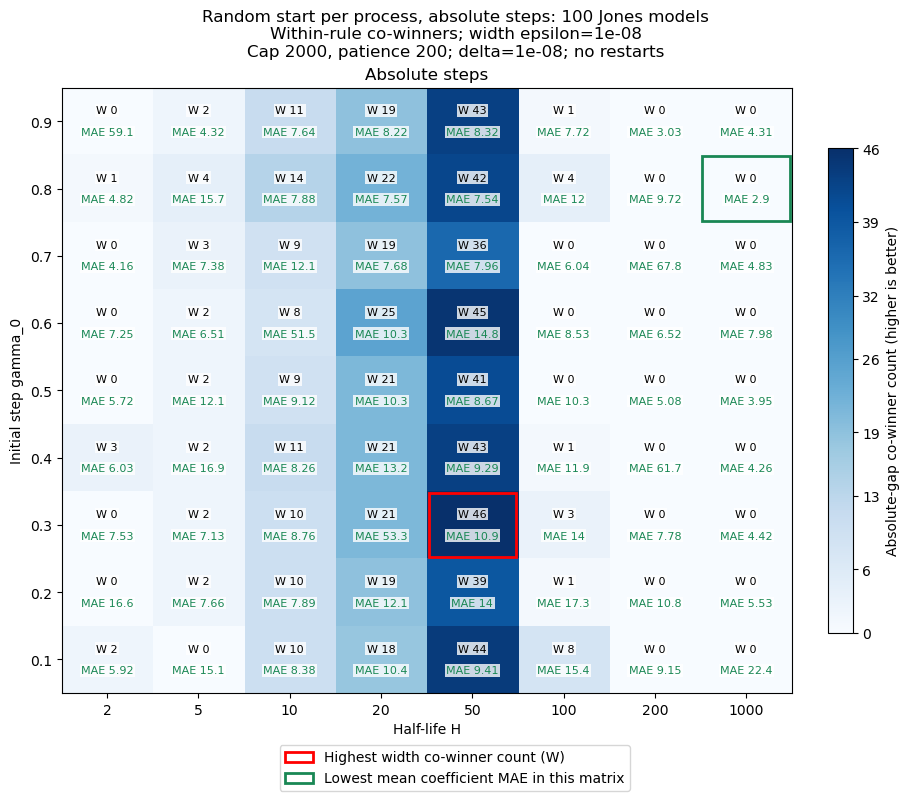

In [9]:
jones_win_figure_stem = f"02_random_per_process_absolute_width_iterations_and_mean_mae_eps_{epsilon_win_tolerance:g}"
fig, jones_win_matrices = plot_tuning_matrices(
    jones_win_ranking, scale_grid, half_life_grid, metric="wins", coefficient_mae_metric="mean_coefficient_mae", maximize=True, precision=0,
    title=(f"Random start per process, absolute steps: {number_of_coefficient_realizations} Jones models\n"
           f"Within-rule co-winners; width epsilon={epsilon_win_tolerance:g}\n"
           f"Cap {max_iterations}, patience {patience}; delta={delta:g}; no restarts"),
    colorbar_label="Absolute-gap co-winner count (higher is better)",
    filename=jones_win_figure_stem, pdf_directory=JONES_PDF_DIR, image_directory=JONES_IMAGE_DIR,
)
plt.show()
plt.close(fig)

In [10]:
with capture_output():
    print("Section 1 winners under the absolute-gap win-count rule:")
    for choice in jones_win_leaders.to_dict("records"):
        print(f"{choice['step_rule']}: scale={choice['step_value']:g}, H={choice['half_life']:g}, "
              f"beta={choice['beta']:.12g}; {int(choice['wins'])}/{number_of_coefficient_realizations} model wins.")
        print(f"Actual gamma0 range across models: [{choice['gamma0_min']:.12g}, {choice['gamma0_max']:.12g}].")
    print(f"One random u_0 per model; direction seed={initial_direction_seed}.")
    print(f"PDF matrices: {JONES_PDF_DIR}")

## 2. Random direction per process — normalized steps

Reuse the exact Jones coefficient vectors, innovation paths and per-model random `initial_directions` from Section 1. Change the initial step to $\gamma_0=s/L$, where $L$ is the exact Euclidean diameter of the empirical four-coordinate point cloud. Use the same scale and half-life grids, iteration cap and patience, with one start and stationarity-triggered restarts disabled. [Shared runner and diameter calculation](../ar_tools/tuning.py).

Pairing assertions check model inputs, seeds, width references and each model's starting direction against Section 1. The matrix shows width co-winner counts within this section's grid and green mean coefficient MAE values. Only width co-winner counts determine the selected configurations. [Counting implementation](../ar_tools/tuning.py).

In [11]:
with capture_output():
    jones_normalized_n_jobs = 4
    jones_normalized_configuration = {
        **jones_configuration,
        "experiment": "jones_random_per_process_normalized_no_restarts",
        "step_rules": ["diameter_normalized"],
        "stationarity_check": False, "max_restarts": 0,
        "diameter": "max_pairwise_euclidean_distance",
        "parallel_workers": jones_normalized_n_jobs,
    }
    jones_normalized_run_id = hashlib.sha256(
        repr(sorted(jones_normalized_configuration.items())).encode()
    ).hexdigest()[:16]
    JONES_NORMALIZED_PDF_DIR = OUTPUT_ROOT / "pdfs" / EXPERIMENT_NAME / f"jones_normalized_{jones_normalized_run_id}"
    JONES_NORMALIZED_IMAGE_DIR = OUTPUT_ROOT / "images" / EXPERIMENT_NAME / f"jones_normalized_{jones_normalized_run_id}"
    for directory in (JONES_NORMALIZED_PDF_DIR, JONES_NORMALIZED_IMAGE_DIR):
        directory.mkdir(parents=True, exist_ok=True)

In [12]:
with capture_output():
    jones_normalized_experiment = tune_jones_ar_realizations(
        T, initial_directions, scale_grid, half_life_grid,
        replications=number_of_coefficient_realizations,
        coefficient_seed=jones_coefficient_seed, process_seed=jones_process_seed,
        burnin=burnin, iterations=max_iterations, patience=patience,
        improvement_tolerance=improvement_tolerance, delta=delta, optimizer_seed=optimizer_seed,
        progress=False, summarize=False, coefficient_diagnostics=False, stationarity_check=False, max_restarts=0,
        step_rule="diameter_normalized", n_jobs=jones_normalized_n_jobs,
    )
    jones_normalized_results = pd.DataFrame(jones_normalized_experiment["results"])
    jones_normalized_cases = pd.DataFrame(jones_normalized_experiment["cases"])
    jones_normalized_pairing_columns = [
        "replication", "T", "coefficient_seed", "process_seed", "phi_1", "phi_2", "phi_3",
        "pacf_1", "pacf_2", "pacf_3", "spectral_radius",
        "population_minimum_width", "empirical_true_direction_width",
        *initial_direction_columns,
    ]
    pd.testing.assert_frame_equal(
        jones_cases[jones_normalized_pairing_columns].sort_values("replication").reset_index(drop=True),
        jones_normalized_cases[jones_normalized_pairing_columns].sort_values("replication").reset_index(drop=True),
        check_exact=True,
    )
    np.testing.assert_allclose(
        jones_normalized_experiment["initial_direction"], initial_directions, atol=1e-15, rtol=0,
    )
    jones_normalized_expected_starts = jones_cases.set_index("replication").loc[
        jones_normalized_results["replication"], initial_direction_columns,
    ].to_numpy()
    np.testing.assert_array_equal(
        jones_normalized_results[initial_direction_columns].to_numpy(), jones_normalized_expected_starts,
    )
    assert len(jones_normalized_cases) == number_of_coefficient_realizations
    assert len(jones_normalized_results) == number_of_coefficient_realizations * len(scale_grid) * len(half_life_grid)
    assert not jones_normalized_results.duplicated(["replication", "T", "candidate_id"]).any()
    assert jones_normalized_results["total_evaluations"].between(1, max_iterations).all()
    assert jones_normalized_results["selected_start"].eq(1).all()
    assert np.isfinite(jones_normalized_results["minimum_width"]).all()
    assert jones_normalized_results.groupby("replication")["cloud_diameter"].nunique().eq(1).all()
    np.testing.assert_allclose(
        jones_normalized_results["gamma0"] * jones_normalized_results["cloud_diameter"],
        jones_normalized_results["step_value"], rtol=2e-15, atol=0,
    )

In [13]:
with capture_output():
    jones_normalized_width_counts, jones_normalized_ranking, jones_normalized_leaders = summarize_width_grid(
        jones_normalized_results,
    )

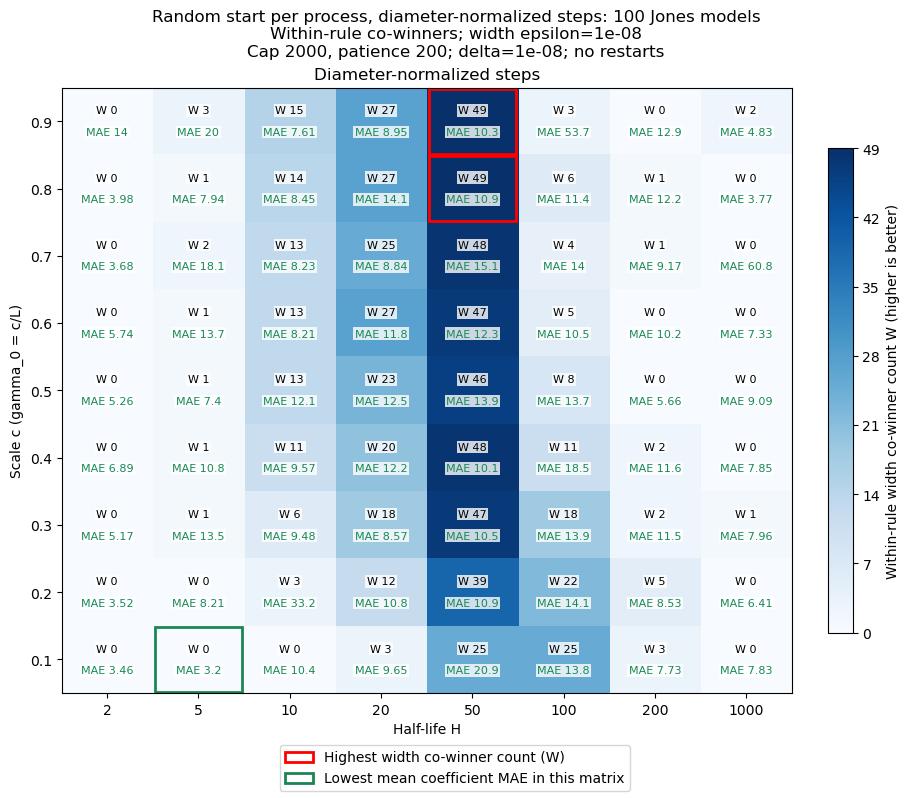

In [14]:
jones_normalized_figure_stem = f"11_random_per_process_normalized_width_iterations_and_mean_mae_eps_{epsilon_win_tolerance:g}"
fig, jones_normalized_win_matrices = plot_tuning_matrices(
    jones_normalized_ranking, scale_grid, half_life_grid,
    metric="wins", coefficient_mae_metric="mean_coefficient_mae", maximize=True, precision=0,
    title=(f"Random start per process, diameter-normalized steps: {number_of_coefficient_realizations} Jones models\n"
           f"Within-rule co-winners; width epsilon={epsilon_win_tolerance:g}\n"
           f"Cap {max_iterations}, patience {patience}; delta={delta:g}; no restarts"),
    colorbar_label="Within-rule width co-winner count W (higher is better)",
    filename=jones_normalized_figure_stem,
    pdf_directory=JONES_NORMALIZED_PDF_DIR, image_directory=JONES_NORMALIZED_IMAGE_DIR,
)
plt.show()
plt.close(fig)

## 3. Direction e1 — absolute steps

Reuse the exact Jones coefficient vectors and innovation paths from Section 1. Use the deterministic starting direction $e_1=(1,0,0,0)$ and the **absolute initial step $\gamma_0=s$**. Search the same scale and half-life grid: 72 configurations with the default settings. [Shared runner](../ar_tools/tuning.py).

Use the shared iteration cap, patience and zero improvement tolerance, with one start and stationarity-triggered restarts disabled. The settings cell prepares the $e_1$ direction and export configuration shared with Section 4. Each section runs and displays its own step rule separately. [Optimizer](../ar_tools/descent.py).

Select using width co-winner counts within this section's grid. Green mean coefficient MAE values are diagnostic and do not affect selection. [Counting implementation](../ar_tools/tuning.py).

In [15]:
with capture_output():
    # Refresh shared helpers when rerunning this section in an existing kernel.
    tuning_tools = importlib.reload(tuning_tools)
    tune_jones_ar_realizations = tuning_tools.tune_jones_ar_realizations
    with plt.rc_context():
        tuning_plot_tools = importlib.reload(tuning_plot_tools)
        plot_tuning_matrices = tuning_plot_tools.plot_tuning_matrices

    e1_initial_direction = np.zeros(embedding_dimension, dtype=float)
    e1_initial_direction[0] = 1.0
    e1_step_rules = ("absolute", "diameter_normalized")
    e1_n_jobs = 4
    e1_configuration = {
        **jones_configuration,
        "experiment": "experiment_4_jones_ar3_e1",
        "initial_direction": e1_initial_direction.tolist(),
        "initialization": "e1", "initial_direction_seed": None,
        "step_rules": list(e1_step_rules),
        "stationarity_check": False, "max_restarts": 0,
        "diameter": "max_pairwise_euclidean_distance",
        "parallel_workers": e1_n_jobs,
        "source_sha256": hashlib.sha256(b"".join(
            (AR_CODE_DIR / "ar_tools" / name).read_bytes()
            for name in ["functions.py", "innovations.py", "descent.py", "tuning.py", "tuning_plots.py", "coefficient_errors.py"]
        )).hexdigest(),
    }
    e1_run_id = hashlib.sha256(repr(sorted(e1_configuration.items())).encode()).hexdigest()[:16]
    E1_PDF_DIR = OUTPUT_ROOT / "pdfs" / EXPERIMENT_NAME / f"experiment4_e1_{e1_run_id}"
    E1_IMAGE_DIR = OUTPUT_ROOT / "images" / EXPERIMENT_NAME / f"experiment4_e1_{e1_run_id}"
    for directory in (E1_PDF_DIR, E1_IMAGE_DIR):
        directory.mkdir(parents=True, exist_ok=True)
    print(f"Experiment 4: {number_of_coefficient_realizations} original Jones models and paths; u_0={e1_initial_direction}.")
    print(f"Rules: gamma0=s and gamma0=s/L; cap={max_iterations}, patience={patience}; one start, no restarts.")
    print(f"Coefficient seed={jones_coefficient_seed}; process seed={jones_process_seed}; run={e1_run_id}.")

In [16]:
with capture_output():
    e1_experiments = {}
    e1_pairing_columns = [
        "replication", "T", "coefficient_seed", "process_seed", "phi_1", "phi_2", "phi_3",
        "pacf_1", "pacf_2", "pacf_3", "spectral_radius",
        "population_minimum_width", "empirical_true_direction_width",
    ]
    for e1_rule in ("absolute",):
        print(f"\nExperiment 4 — {e1_rule}", flush=True)
        e1_experiments[e1_rule] = tune_jones_ar_realizations(
            T, e1_initial_direction, scale_grid, half_life_grid,
            replications=number_of_coefficient_realizations,
            coefficient_seed=jones_coefficient_seed, process_seed=jones_process_seed,
            burnin=burnin, iterations=max_iterations, patience=patience,
            improvement_tolerance=improvement_tolerance, delta=delta, optimizer_seed=optimizer_seed,
            progress=True, summarize=False, coefficient_diagnostics=False, stationarity_check=False, max_restarts=0,
            step_rule=e1_rule, n_jobs=e1_n_jobs,
        )
        e1_rule_cases = pd.DataFrame(e1_experiments[e1_rule]["cases"])
        pd.testing.assert_frame_equal(
            jones_cases[e1_pairing_columns].sort_values("replication").reset_index(drop=True),
            e1_rule_cases[e1_pairing_columns].sort_values("replication").reset_index(drop=True),
            check_exact=True,
        )
        np.testing.assert_array_equal(e1_experiments[e1_rule]["initial_direction"], e1_initial_direction)

    e1_absolute_results = pd.DataFrame(e1_experiments["absolute"]["results"])

### 3.1 Width co-winner counts and iteration usage

In [17]:
with capture_output():
    e1_absolute_width_counts, e1_absolute_ranking, e1_absolute_leaders = summarize_width_grid(
        e1_absolute_results,
    )

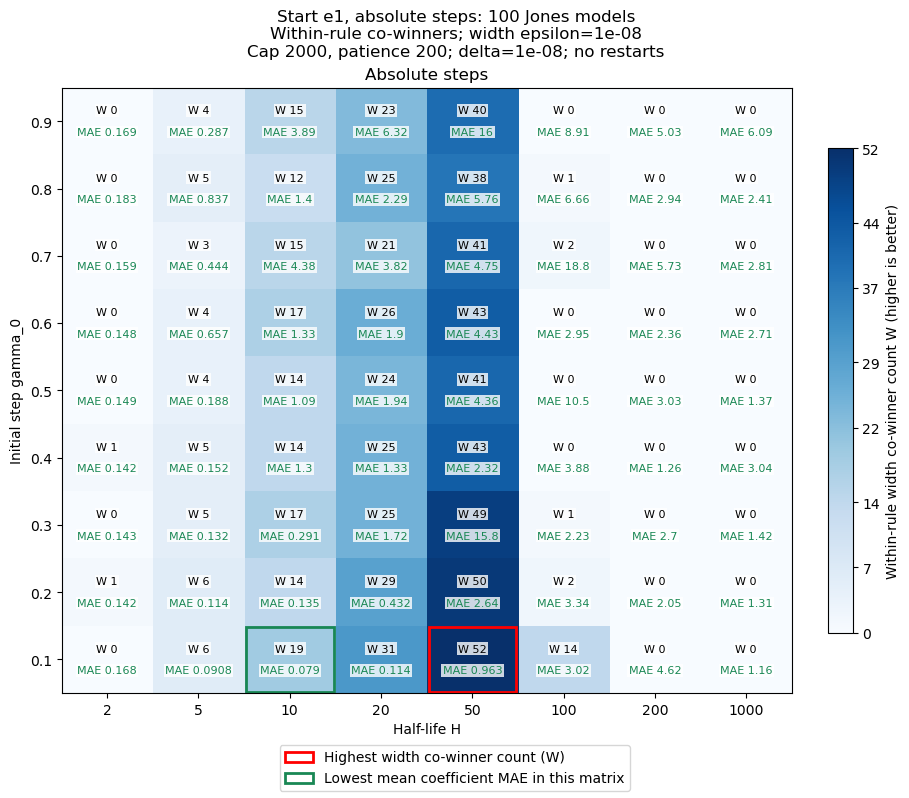

In [18]:
e1_absolute_figure_stem = f"10_e1_absolute_width_iterations_and_mean_mae_eps_{epsilon_win_tolerance:g}"
fig, e1_absolute_win_matrices = plot_tuning_matrices(
    e1_absolute_ranking, scale_grid, half_life_grid,
    metric="wins", coefficient_mae_metric="mean_coefficient_mae", maximize=True, precision=0,
    title=(f"Start e1, absolute steps: {number_of_coefficient_realizations} Jones models\n"
           f"Within-rule co-winners; width epsilon={epsilon_win_tolerance:g}\n"
           f"Cap {max_iterations}, patience {patience}; delta={delta:g}; no restarts"),
    colorbar_label="Within-rule width co-winner count W (higher is better)",
    filename=e1_absolute_figure_stem, pdf_directory=E1_PDF_DIR, image_directory=E1_IMAGE_DIR,
)
plt.show()
plt.close(fig)

## 4. Direction e1 — normalized steps

Reuse the models, paths, deterministic $e_1$ direction and shared settings from Sections 1 and 3. Change the initial step to **$\gamma_0=s/L$**, where $L$ is the exact Euclidean diameter of each empirical point cloud. The scale and half-life grid again has 72 configurations with the default settings. [Shared runner and diameter calculation](../ar_tools/tuning.py).

Use one start, the same iteration cap and patience, and stationarity-triggered restarts disabled. Select using width co-winner counts within this section's grid. Green mean coefficient MAE values are diagnostic and do not affect selection. Section 5 combines the completed results from all four experiments. [Optimizer](../ar_tools/descent.py), [counting implementation](../ar_tools/tuning.py).

In [19]:
with capture_output():
    for e1_rule in ("diameter_normalized",):
        print(f"\nExperiment 4 — {e1_rule}", flush=True)
        e1_experiments[e1_rule] = tune_jones_ar_realizations(
            T, e1_initial_direction, scale_grid, half_life_grid,
            replications=number_of_coefficient_realizations,
            coefficient_seed=jones_coefficient_seed, process_seed=jones_process_seed,
            burnin=burnin, iterations=max_iterations, patience=patience,
            improvement_tolerance=improvement_tolerance, delta=delta, optimizer_seed=optimizer_seed,
            progress=True, summarize=False, coefficient_diagnostics=False, stationarity_check=False, max_restarts=0,
            step_rule=e1_rule, n_jobs=e1_n_jobs,
        )
        e1_rule_cases = pd.DataFrame(e1_experiments[e1_rule]["cases"])
        pd.testing.assert_frame_equal(
            jones_cases[e1_pairing_columns].sort_values("replication").reset_index(drop=True),
            e1_rule_cases[e1_pairing_columns].sort_values("replication").reset_index(drop=True),
            check_exact=True,
        )
        np.testing.assert_array_equal(e1_experiments[e1_rule]["initial_direction"], e1_initial_direction)

    e1_normalized_results = pd.DataFrame(e1_experiments["diameter_normalized"]["results"])

### 4.1 Width co-winner counts and iteration usage

In [20]:
with capture_output():
    e1_normalized_width_counts, e1_normalized_ranking, e1_normalized_leaders = summarize_width_grid(
        e1_normalized_results,
    )

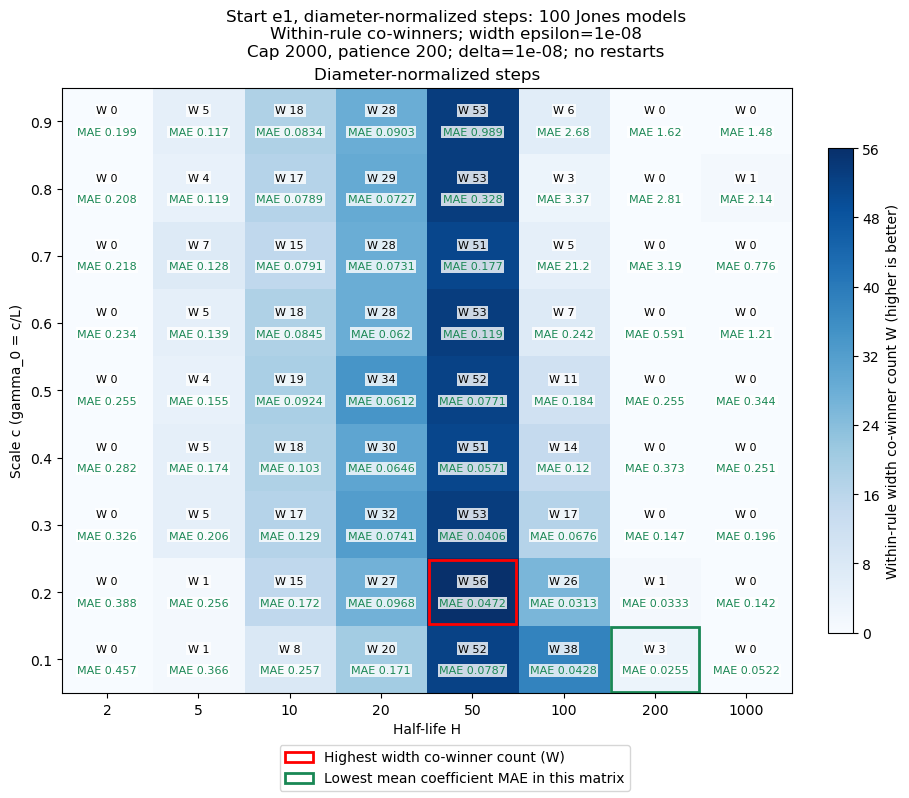

In [21]:
e1_normalized_figure_stem = f"10_e1_diameter_normalized_width_iterations_and_mean_mae_eps_{epsilon_win_tolerance:g}"
fig, e1_normalized_win_matrices = plot_tuning_matrices(
    e1_normalized_ranking, scale_grid, half_life_grid,
    metric="wins", coefficient_mae_metric="mean_coefficient_mae", maximize=True, precision=0,
    title=(f"Start e1, diameter-normalized steps: {number_of_coefficient_realizations} Jones models\n"
           f"Within-rule co-winners; width epsilon={epsilon_win_tolerance:g}\n"
           f"Cap {max_iterations}, patience {patience}; delta={delta:g}; no restarts"),
    colorbar_label="Within-rule width co-winner count W (higher is better)",
    filename=e1_normalized_figure_stem, pdf_directory=E1_PDF_DIR, image_directory=E1_IMAGE_DIR,
)
plt.show()
plt.close(fig)

## 5. Common comparison of all four variants

This section reuses the completed results from Sections 1–4 and runs no further descents. It assembles the paired results, computes a supporting width-only comparison of the two $e_1$ variants, and then recomputes width co-winner counts across **all four grids together** for the final two-by-two figure. [Counting implementation](../ar_tools/tuning.py).

The final figure has starting directions as rows and step rules as columns. Each cell shows W (width co-winner count against the common reference) and green MAE (mean coefficient MAE across all runs for that configuration). All panels use the same width-count color scale. Red boxes identify all configurations with the highest width count across the four grids. Green boxes identify the lowest mean coefficient MAE across all four grids together; all exact ties in unrounded values are retained. MAE never enters selection. The MAE values are identical to the corresponding individual matrices because they use the same runs.

### 5.1 Assemble results and verify the paired design


In [22]:
with capture_output():
    e1_results = pd.concat([
        pd.DataFrame(e1_experiments[rule]["results"]) for rule in e1_step_rules
    ], ignore_index=True)
    e1_expected_per_rule = number_of_coefficient_realizations * len(scale_grid) * len(half_life_grid)
    assert len(e1_results) == 2 * e1_expected_per_rule
    assert e1_results.groupby("step_rule").size().eq(e1_expected_per_rule).all()
    assert not e1_results.duplicated(["replication", "T", "candidate_id"]).any()
    assert e1_results["total_evaluations"].between(1, max_iterations).all()
    assert e1_results["selected_start"].eq(1).all()
    assert np.isfinite(e1_results["minimum_width"]).all()
    e1_scaled_rows = e1_results.loc[e1_results["step_rule"].eq("diameter_normalized")]
    assert e1_scaled_rows.groupby("replication")["cloud_diameter"].nunique().eq(1).all()
    np.testing.assert_allclose(
        e1_scaled_rows["gamma0"] * e1_scaled_rows["cloud_diameter"],
        e1_scaled_rows["step_value"], rtol=2e-15, atol=0,
    )
    np.testing.assert_array_equal(
        e1_results.loc[e1_results["step_rule"].eq("absolute"), "gamma0"],
        e1_results.loc[e1_results["step_rule"].eq("absolute"), "step_value"],
    )
    print(f"\nCompleted {len(e1_results):,} configurations on the same {number_of_coefficient_realizations} models and paths.")
    print("Exact model coefficients, partial autocorrelations, seeds and reference widths match original Experiment 3 for both rules.")
    print(f"Total evaluated directions: {int(e1_results['total_evaluations'].sum()):,}.")

### 5.2 Supporting comparison of the two e1 variants

Within-rule counts use different reference minima. Recompute width co-winner counts over both $e_1$ grids together (144 configurations by default) on the same models. Retain every configuration tied for the highest count. The final figure below uses the broader four-variant reference. [Counting implementation](../ar_tools/tuning.py).

In [23]:
with capture_output():
    e1_common_width_counts, e1_common_ranking, e1_common_leaders = summarize_width_grid(e1_results)

### 5.3 Common reference across all four variants

Rows are **random direction per process** and **$e_1$**; columns are **absolute steps** and **diameter-normalized steps**. All variants share models, paths, iteration cap and patience. [Shared runner](../ar_tools/tuning.py).

Recompute width co-winner credits against **all four grids together** (288 configurations per path by default). Each configuration is identified by initialization, step rule, scale and half-life. All configurations within the width tolerance receive +1, and every tied overall leader receives a red outline. This common reference differs from the individual sections' reference minima. [Counting rule](../ar_tools/tuning.py), `summarize_configuration_wins`.

Black W values and the background color show width co-winner counts. Green MAE values give mean coefficient MAE. Both remain identical to their corresponding individual matrices because no additional descent is run. Green outlines identify the lowest finite, unrounded mean coefficient MAE across all four grids together, retaining every exact tie. An inset green outline preserves visibility when that cell also has a red outline. Only width counts determine width-based selection.

In [24]:
with capture_output():
    factorial_results = pd.concat([
        jones_results.assign(initialization="random_per_process"),
        jones_normalized_results.assign(initialization="random_per_process"),
        e1_results.assign(initialization="e1"),
    ], ignore_index=True)
    factorial_results["within_variant_candidate_id"] = factorial_results["candidate_id"]
    factorial_results["candidate_id"] = factorial_results["initialization"] + "::" + factorial_results["candidate_id"]
    factorial_grid_size = len(scale_grid) * len(half_life_grid)
    assert len(factorial_results) == 4 * factorial_grid_size * number_of_coefficient_realizations
    assert factorial_results["candidate_id"].nunique() == 4 * factorial_grid_size
    assert not factorial_results.duplicated(["replication", "T", "candidate_id"]).any()
    assert factorial_results.groupby(["replication", "T"]).size().eq(4 * factorial_grid_size).all()

    factorial_width_counts, factorial_ranking, factorial_width_leaders = summarize_width_grid(factorial_results)
    factorial_labels = factorial_results[["candidate_id", "initialization"]].drop_duplicates()
    factorial_ranking = factorial_ranking.merge(factorial_labels, on="candidate_id", validate="one_to_one")
    factorial_width_leaders = factorial_ranking.loc[
        factorial_ranking["wins"].eq(factorial_ranking["wins"].max())
    ].copy()

    factorial_configuration = {
        **jones_configuration,
        "experiment": "jones_start_step_2x2_common_reference",
        "initial_directions": {"random_per_process": initial_directions.tolist(), "e1": e1_initial_direction.tolist()},
        "step_rules": ["absolute", "diameter_normalized"],
        "stationarity_check": False, "max_restarts": 0,
        "reference": "all_four_start_step_grids",
    }
    factorial_run_id = hashlib.sha256(repr(sorted(factorial_configuration.items())).encode()).hexdigest()[:16]
    FACTORIAL_PDF_DIR = OUTPUT_ROOT / "pdfs" / EXPERIMENT_NAME / f"factorial_2x2_{factorial_run_id}"
    FACTORIAL_IMAGE_DIR = OUTPUT_ROOT / "images" / EXPERIMENT_NAME / f"factorial_2x2_{factorial_run_id}"
    for directory in (FACTORIAL_PDF_DIR, FACTORIAL_IMAGE_DIR):
        directory.mkdir(parents=True, exist_ok=True)

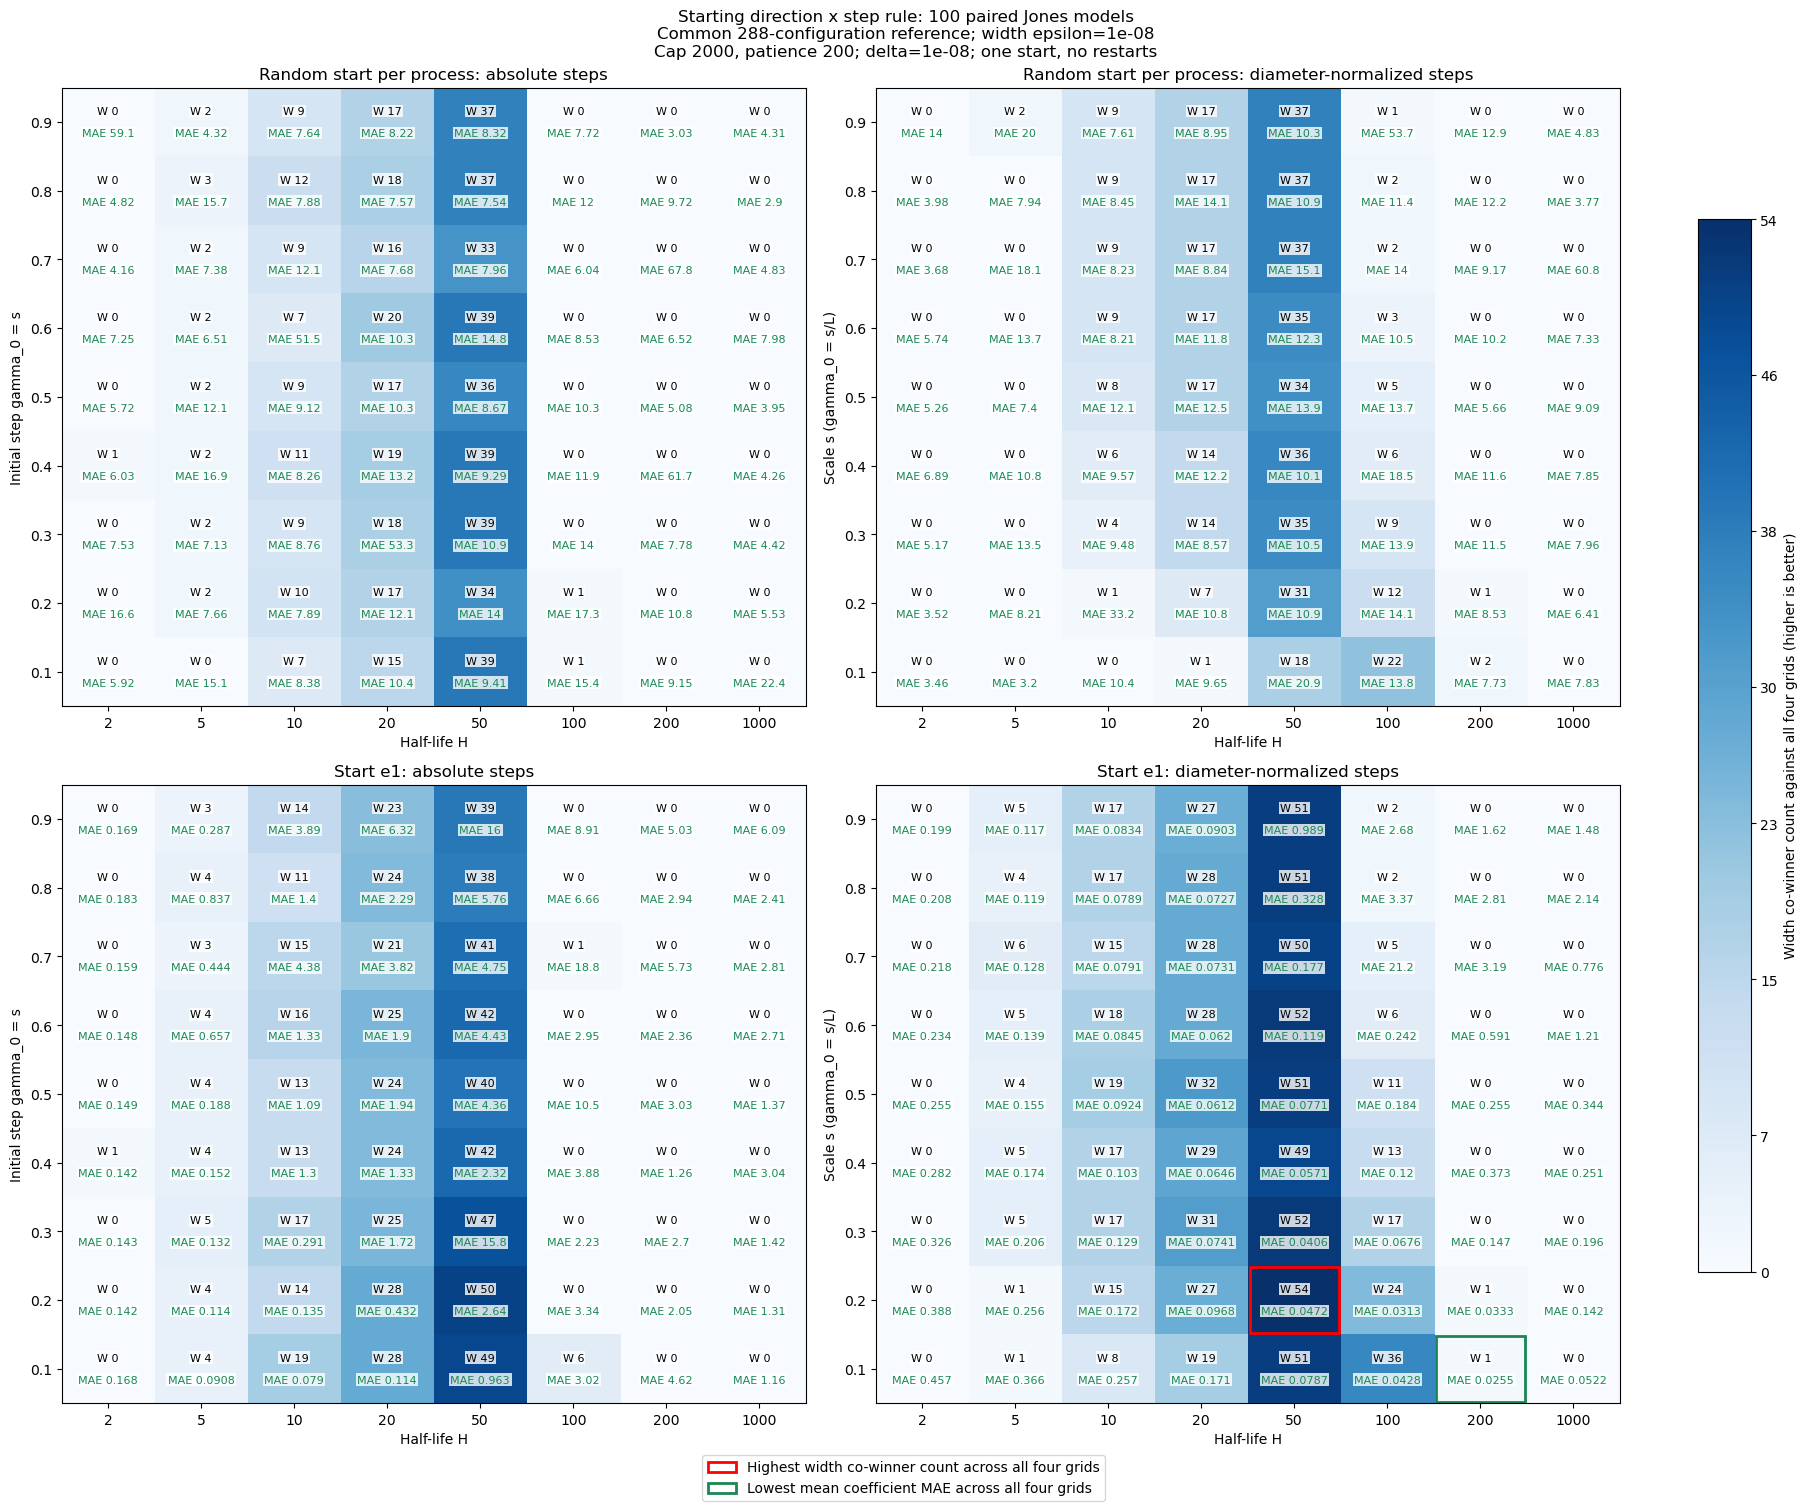

In [25]:
from matplotlib.patches import Patch, Rectangle
from Code.Code_AR_processes.ar_tools.plotting_functions import save_figure
from Code.Code_AR_processes.ar_tools.tuning_plots import annotate_tuning_cell, COEFFICIENT_MAE_COLOR

factorial_win_matrices = {}
fig, factorial_axes = plt.subplots(2, 2, figsize=(18, 15), constrained_layout=True)
factorial_color_max = max(1, int(factorial_ranking["wins"].max()))
factorial_best_width = factorial_ranking["wins"].max()
factorial_finite_mae = factorial_ranking.loc[
    np.isfinite(factorial_ranking["mean_coefficient_mae"]), "mean_coefficient_mae"
]
factorial_best_mae = factorial_finite_mae.min()
for factorial_row, factorial_initialization in enumerate(("random_per_process", "e1")):
    for factorial_column, factorial_rule in enumerate(("absolute", "diameter_normalized")):
        factorial_ax = factorial_axes[factorial_row, factorial_column]
        factorial_panel = factorial_ranking.loc[
            factorial_ranking["initialization"].eq(factorial_initialization)
            & factorial_ranking["step_rule"].eq(factorial_rule)
        ]
        factorial_width_matrix = factorial_panel.pivot(index="step_value", columns="half_life", values="wins").reindex(
            index=scale_grid, columns=half_life_grid,
        )
        factorial_mae_matrix = factorial_panel.pivot(
            index="step_value", columns="half_life", values="mean_coefficient_mae",
        ).reindex(index=scale_grid, columns=half_life_grid)
        assert factorial_width_matrix.notna().all().all()
        factorial_win_matrices[(factorial_initialization, factorial_rule)] = factorial_width_matrix
        factorial_image = factorial_ax.imshow(
            factorial_width_matrix.to_numpy(), origin="lower", aspect="auto", cmap="Blues",
            vmin=0, vmax=factorial_color_max,
        )
        for factorial_i in range(len(scale_grid)):
            for factorial_j in range(len(half_life_grid)):
                factorial_w = int(factorial_width_matrix.iloc[factorial_i, factorial_j])
                annotate_tuning_cell(
                    factorial_ax, factorial_j, factorial_i, f"W {factorial_w}",
                    mean_coefficient_mae=factorial_mae_matrix.iloc[factorial_i, factorial_j],
                )
                if factorial_w == factorial_best_width:
                    factorial_ax.add_patch(Rectangle(
                        (factorial_j - .48, factorial_i - .48), .96, .96,
                        fill=False, edgecolor="red", linewidth=2,
                    ))
                factorial_mae = factorial_mae_matrix.iloc[factorial_i, factorial_j]
                if np.isfinite(factorial_mae) and factorial_mae == factorial_best_mae:
                    factorial_extent = .40 if factorial_w == factorial_best_width else .48
                    factorial_ax.add_patch(Rectangle(
                        (factorial_j - factorial_extent, factorial_i - factorial_extent),
                        2 * factorial_extent, 2 * factorial_extent,
                        fill=False, edgecolor=COEFFICIENT_MAE_COLOR, linewidth=2,
                    ))
        factorial_start_label = "Random start per process" if factorial_initialization == "random_per_process" else "Start e1"
        factorial_step_label = "absolute steps" if factorial_rule == "absolute" else "diameter-normalized steps"
        factorial_ax.set(
            xticks=np.arange(len(half_life_grid)), xticklabels=[f"{h:g}" for h in half_life_grid],
            yticks=np.arange(len(scale_grid)), yticklabels=[f"{s:g}" for s in scale_grid],
            xlabel="Half-life H",
            ylabel="Initial step gamma_0 = s" if factorial_rule == "absolute" else "Scale s (gamma_0 = s/L)",
            title=f"{factorial_start_label}: {factorial_step_label}",
        )
fig.suptitle(
    f"Starting direction x step rule: {number_of_coefficient_realizations} paired Jones models\n"
    f"Common {4 * factorial_grid_size}-configuration reference; width epsilon={epsilon_win_tolerance:g}\n"
    f"Cap {max_iterations}, patience {patience}; delta={delta:g}; one start, no restarts",
)
factorial_colorbar = fig.colorbar(
    factorial_image, ax=factorial_axes.ravel().tolist(), shrink=.8,
    label="Width co-winner count against all four grids (higher is better)",
)
factorial_colorbar.set_ticks(np.unique(np.linspace(
    0, factorial_color_max, min(factorial_color_max + 1, 8), dtype=int,
)))
fig.legend(handles=[
    Patch(fill=False, edgecolor="red", linewidth=2, label="Highest width co-winner count across all four grids"),
    Patch(fill=False, edgecolor=COEFFICIENT_MAE_COLOR, linewidth=2, label="Lowest mean coefficient MAE across all four grids"),
], loc="outside lower center", ncol=1)
factorial_figure_stem = "12_starting_direction_step_rule_2x2_width_iterations_and_mean_mae"
save_figure(fig, factorial_figure_stem, pdf_directory=FACTORIAL_PDF_DIR, image_directory=FACTORIAL_IMAGE_DIR)
plt.show()
plt.close(fig)

### 5.4 Mean coefficient MAE versus half-life

Rows compare absolute and diameter-normalized steps; columns compare random starts per process and $e_1$. Each curve represents one scale $s$. The figure reuses the mean coefficient MAEs in `factorial_ranking`, with shared axes and the same scale colors in all panels. Undefined means appear as gaps. Logarithmic axes can be switched off in the cell. PDF and PNG are saved automatically when you run it. [MAE computation](../ar_tools/coefficient_errors.py).


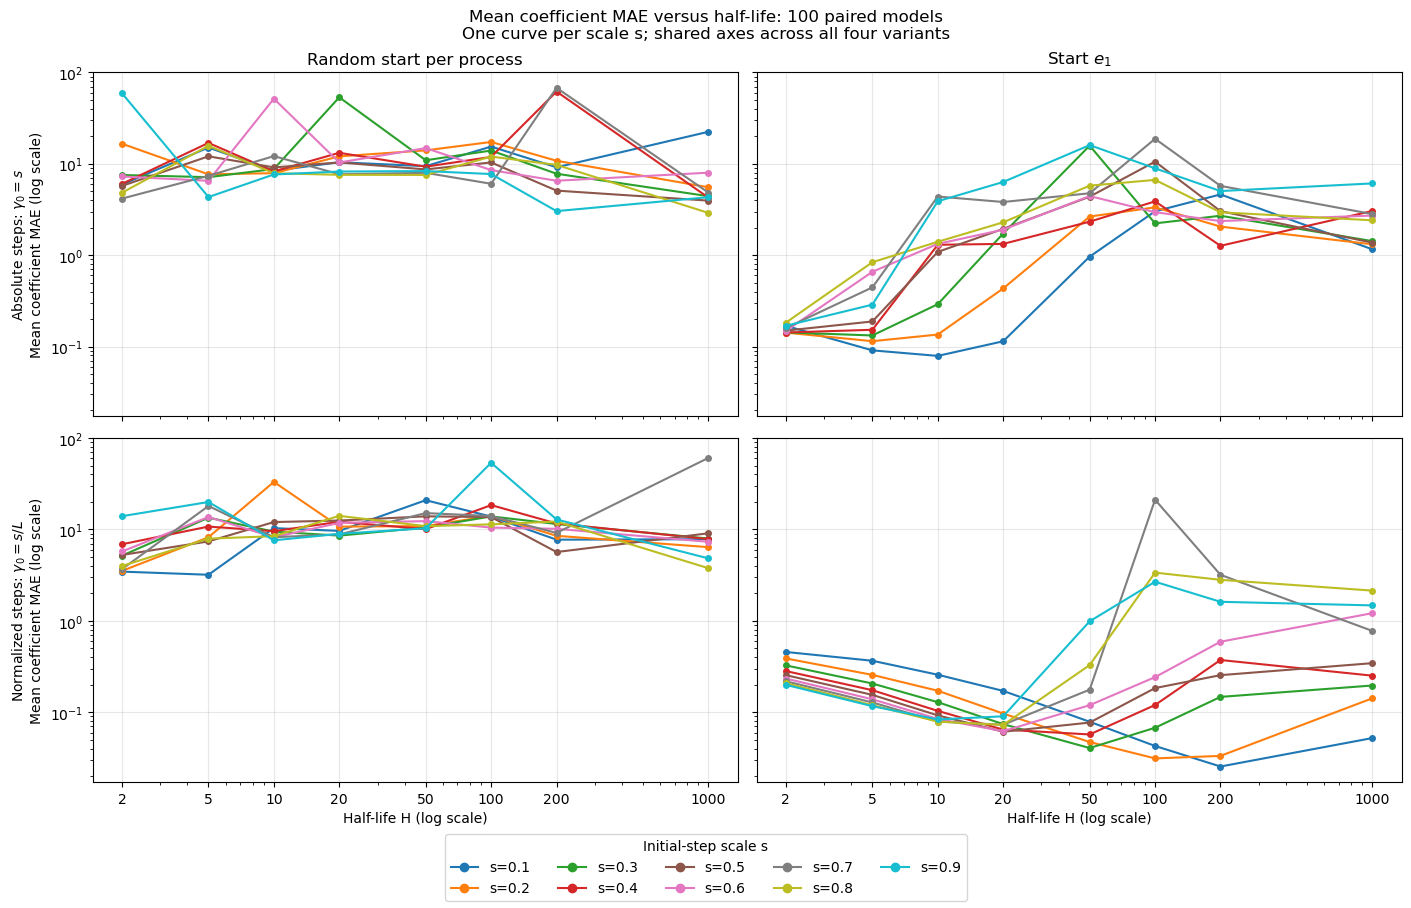

In [26]:
# Reuse the completed tuning results; this cell runs no further descents.
from Code.Code_AR_processes.ar_tools.plotting_functions import save_figure
from matplotlib.lines import Line2D

# Logarithmic axes help display the full H range and the different MAE magnitudes.
mae_curves_log_x = True
mae_curves_log_y = True  # Set False for a linear MAE axis.

mae_curve_required = {"initialization", "step_rule", "step_value", "half_life", "mean_coefficient_mae"}
if "factorial_ranking" not in globals() or not mae_curve_required.issubset(factorial_ranking.columns):
    raise RuntimeError("Run Sections 1-5 first to prepare factorial_ranking.")
mae_curve_finite = factorial_ranking.loc[
    np.isfinite(factorial_ranking["mean_coefficient_mae"]), "mean_coefficient_mae",
]
if mae_curve_finite.empty or (mae_curve_finite < 0).any():
    raise ValueError("The figure requires finite, nonnegative coefficient MAEs.")
# Preserve exact zero errors by switching to a linear axis when necessary.
mae_curve_use_log_y = mae_curves_log_y and mae_curve_finite.gt(0).all()
mae_curve_colors = plt.get_cmap("tab10")(np.linspace(0, 1, len(scale_grid)))
mae_curve_fig, mae_curve_axes = plt.subplots(
    2, 2, figsize=(14, 9), sharex=True, sharey=True, constrained_layout=True,
)
for mae_curve_row, mae_curve_rule in enumerate(("absolute", "diameter_normalized")):
    for mae_curve_col, mae_curve_start in enumerate(("random_per_process", "e1")):
        mae_curve_ax = mae_curve_axes[mae_curve_row, mae_curve_col]
        mae_curve_panel = factorial_ranking.loc[
            factorial_ranking["initialization"].eq(mae_curve_start)
            & factorial_ranking["step_rule"].eq(mae_curve_rule)
        ]
        mae_curve_matrix = mae_curve_panel.pivot(
            index="step_value", columns="half_life", values="mean_coefficient_mae",
        ).reindex(index=scale_grid, columns=half_life_grid)
        for mae_curve_scale, mae_curve_color in zip(scale_grid, mae_curve_colors):
            mae_curve_values = mae_curve_matrix.loc[mae_curve_scale].to_numpy(dtype=float)
            mae_curve_values = np.where(np.isfinite(mae_curve_values), mae_curve_values, np.nan)
            mae_curve_ax.plot(
                half_life_grid, mae_curve_values, marker="o", markersize=4,
                linewidth=1.5, color=mae_curve_color,
            )
        if mae_curves_log_x:
            mae_curve_ax.set_xscale("log")
        if mae_curve_use_log_y:
            mae_curve_ax.set_yscale("log")
        mae_curve_ax.set_xticks(half_life_grid, labels=[f"{h:g}" for h in half_life_grid])
        mae_curve_ax.grid(True, which="major", alpha=.3)
        if mae_curve_row == 0:
            mae_curve_ax.set_title("Random start per process" if mae_curve_col == 0 else r"Start $e_1$")
        if mae_curve_col == 0:
            mae_curve_rule_label = (r"Absolute steps: $\gamma_0=s$" if mae_curve_rule == "absolute"
                                    else r"Normalized steps: $\gamma_0=s/L$")
            mae_curve_ax.set_ylabel(
                mae_curve_rule_label + "\nMean coefficient MAE"
                + (" (log scale)" if mae_curve_use_log_y else "")
            )
        if mae_curve_row == 1:
            mae_curve_ax.set_xlabel("Half-life H" + (" (log scale)" if mae_curves_log_x else ""))
mae_curve_fig.suptitle(
    f"Mean coefficient MAE versus half-life: {number_of_coefficient_realizations} paired models\n"
    "One curve per scale s; shared axes across all four variants"
)
mae_curve_fig.legend(
    handles=[Line2D([0], [0], color=color, marker="o", linewidth=1.5, label=f"s={scale:g}")
             for scale, color in zip(scale_grid, mae_curve_colors)],
    loc="outside lower center", ncol=min(5, len(scale_grid)), title="Initial-step scale s",
)
save_figure(
    mae_curve_fig, "13_mean_coefficient_mae_vs_half_life_2x2",
    pdf_directory=FACTORIAL_PDF_DIR, image_directory=FACTORIAL_IMAGE_DIR,
)
plt.show()
plt.close(mae_curve_fig)


## 6. One AR process, 10 independent realizations: mean achieved width

Draw one Jones AR(3) coefficient vector and hold it fixed. Simulate 10 realizations using distinct innovation seeds. Reuse each realization across every configuration and all four variants. Draw one random starting direction per realization and share it across both random-start step rules and all their configurations; the other two variants start at $e_1$. [Sampler](../ar_tools/functions.py), [paired runner](../ar_tools/tuning.py).

Reuse the shared scale grid $c$ and decay grid $\beta=2^{-1/H}$, iteration cap, patience and delta. Each cell displays the arithmetic mean of the best achieved width from all 10 descents for that configuration. All four panels share a color scale. Red outlines mark the overall lowest unrounded mean, including exact ties. No coefficient MAE or win counts enter this experiment. Only its matrix is displayed and exported as PDF/PNG.

This section needs only the shared imports and settings cells; earlier experiments do not need to be rerun. Change `single_ar_realizations` to 100 later. Changing that count preserves the coefficient vector.


In [27]:
# Run the shared imports/settings cells, then this section independently.
from Code.Code_AR_processes.ar_tools.functions import jones_ar_coefficients
tuning_tools = importlib.reload(tuning_tools)

single_ar_realizations = 10  # Change to 100 later; the coefficients stay fixed.
single_ar_coefficient_seed = 20261026
single_ar_process_seed = 20261027
single_ar_direction_seed = 20261028
single_ar_n_jobs = 4
single_ar_phi = jones_ar_coefficients(p, rng=single_ar_coefficient_seed)
single_ar_initial_directions = np.random.default_rng(single_ar_direction_seed).normal(
    size=(single_ar_realizations, embedding_dimension),
)
single_ar_initial_directions /= np.linalg.norm(single_ar_initial_directions, axis=1, keepdims=True)
single_ar_e1 = np.zeros(embedding_dimension)
single_ar_e1[0] = 1.
single_ar_beta_grid = np.exp2(-1. / half_life_grid)
single_ar_configuration = {
    "experiment": "one_ar_process_mean_achieved_width", "phi": single_ar_phi.tolist(),
    "replications": single_ar_realizations, "T": int(T), "burnin": int(burnin),
    "coefficient_seed": single_ar_coefficient_seed, "process_seed": single_ar_process_seed,
    "initial_direction_seed": single_ar_direction_seed, "optimizer_seed": int(optimizer_seed),
    "scale_grid": scale_grid.tolist(), "half_life_grid": half_life_grid.tolist(),
    "beta_grid": single_ar_beta_grid.tolist(), "max_iterations": int(max_iterations),
    "patience": int(patience), "improvement_tolerance": float(improvement_tolerance),
    "delta": float(delta), "starts": 1, "stationarity_check": False, "max_restarts": 0,
    "selection": "lowest_mean_achieved_width", "source_sha256": hashlib.sha256(b"".join(
        (AR_CODE_DIR / "ar_tools" / name).read_bytes()
        for name in ("functions.py", "innovations.py", "descent.py", "tuning.py")
    )).hexdigest(),
}
single_ar_run_id = hashlib.sha256(repr(sorted(single_ar_configuration.items())).encode()).hexdigest()[:16]
SINGLE_AR_PDF_DIR = OUTPUT_ROOT / "pdfs" / EXPERIMENT_NAME / f"single_ar_mean_width_{single_ar_run_id}"
SINGLE_AR_IMAGE_DIR = OUTPUT_ROOT / "images" / EXPERIMENT_NAME / f"single_ar_mean_width_{single_ar_run_id}"
for single_ar_directory in (SINGLE_AR_PDF_DIR, SINGLE_AR_IMAGE_DIR):
    single_ar_directory.mkdir(parents=True, exist_ok=True)


In [28]:
with capture_output():
    single_ar_experiments = {}
    single_ar_frames = []
    single_ar_pairing_columns = [
        "replication", "T", "process_seed", "phi_1", "phi_2", "phi_3",
        "population_minimum_width", "empirical_true_direction_width",
    ]
    single_ar_start_columns = [f"initial_u_{j}" for j in range(embedding_dimension)]
    single_ar_reference_cases = None
    for single_ar_start, single_ar_directions in (
        ("random_per_realization", single_ar_initial_directions), ("e1", single_ar_e1),
    ):
        for single_ar_rule in ("absolute", "diameter_normalized"):
            single_ar_experiment = tuning_tools.tune_fixed_ar_realizations(
                single_ar_phi, T, single_ar_directions, scale_grid, half_life_grid,
                replications=single_ar_realizations, process_seed=single_ar_process_seed,
                burnin=burnin, iterations=max_iterations, patience=patience,
                improvement_tolerance=improvement_tolerance, delta=delta,
                optimizer_seed=optimizer_seed, step_rule=single_ar_rule,
                stationarity_check=False, max_restarts=0, coefficient_diagnostics=False,
                n_jobs=single_ar_n_jobs, progress=False, summarize=False,
            )
            single_ar_experiments[(single_ar_start, single_ar_rule)] = single_ar_experiment
            single_ar_cases = pd.DataFrame(single_ar_experiment["cases"]).sort_values("replication")
            single_ar_case_reference = single_ar_cases[single_ar_pairing_columns].reset_index(drop=True)
            if single_ar_reference_cases is None:
                single_ar_reference_cases = single_ar_case_reference
            pd.testing.assert_frame_equal(single_ar_case_reference, single_ar_reference_cases, check_exact=True)
            assert single_ar_cases["process_seed"].nunique() == single_ar_realizations
            single_ar_expected_starts = (
                single_ar_initial_directions if single_ar_start == "random_per_realization"
                else np.tile(single_ar_e1, (single_ar_realizations, 1))
            )
            np.testing.assert_allclose(
                single_ar_cases[single_ar_start_columns].to_numpy(), single_ar_expected_starts,
                atol=1e-15, rtol=0,
            )
            single_ar_frame = pd.DataFrame(single_ar_experiment["results"]).assign(initialization=single_ar_start)
            np.testing.assert_array_equal(
                single_ar_frame[single_ar_start_columns].to_numpy(),
                single_ar_cases.set_index("replication").loc[
                    single_ar_frame["replication"], single_ar_start_columns,
                ].to_numpy(),
            )
            single_ar_frames.append(single_ar_frame)
    single_ar_results = pd.concat(single_ar_frames, ignore_index=True)
    assert len(single_ar_results) == 4 * len(scale_grid) * len(half_life_grid) * single_ar_realizations
    assert not single_ar_results.duplicated(["initialization", "candidate_id", "replication"]).any()
    assert np.isfinite(single_ar_results["minimum_width"]).all()
    assert single_ar_results["selected_start"].eq(1).all()
    assert single_ar_results["total_evaluations"].between(1, max_iterations).all()
    np.testing.assert_array_equal(
        single_ar_results[["phi_1", "phi_2", "phi_3"]].to_numpy(),
        np.tile(single_ar_phi, (len(single_ar_results), 1)),
    )
    single_ar_summary = single_ar_results.groupby(
        ["initialization", "step_rule", "candidate_id", "step_value", "half_life", "beta"],
        as_index=False,
    ).agg(mean_achieved_width=("minimum_width", "mean"), realizations=("replication", "size"))
    assert single_ar_summary["realizations"].eq(single_ar_realizations).all()
    single_ar_lowest_mean = single_ar_summary["mean_achieved_width"].min()
    single_ar_leaders = single_ar_summary.loc[
        single_ar_summary["mean_achieved_width"].eq(single_ar_lowest_mean)
    ].copy()


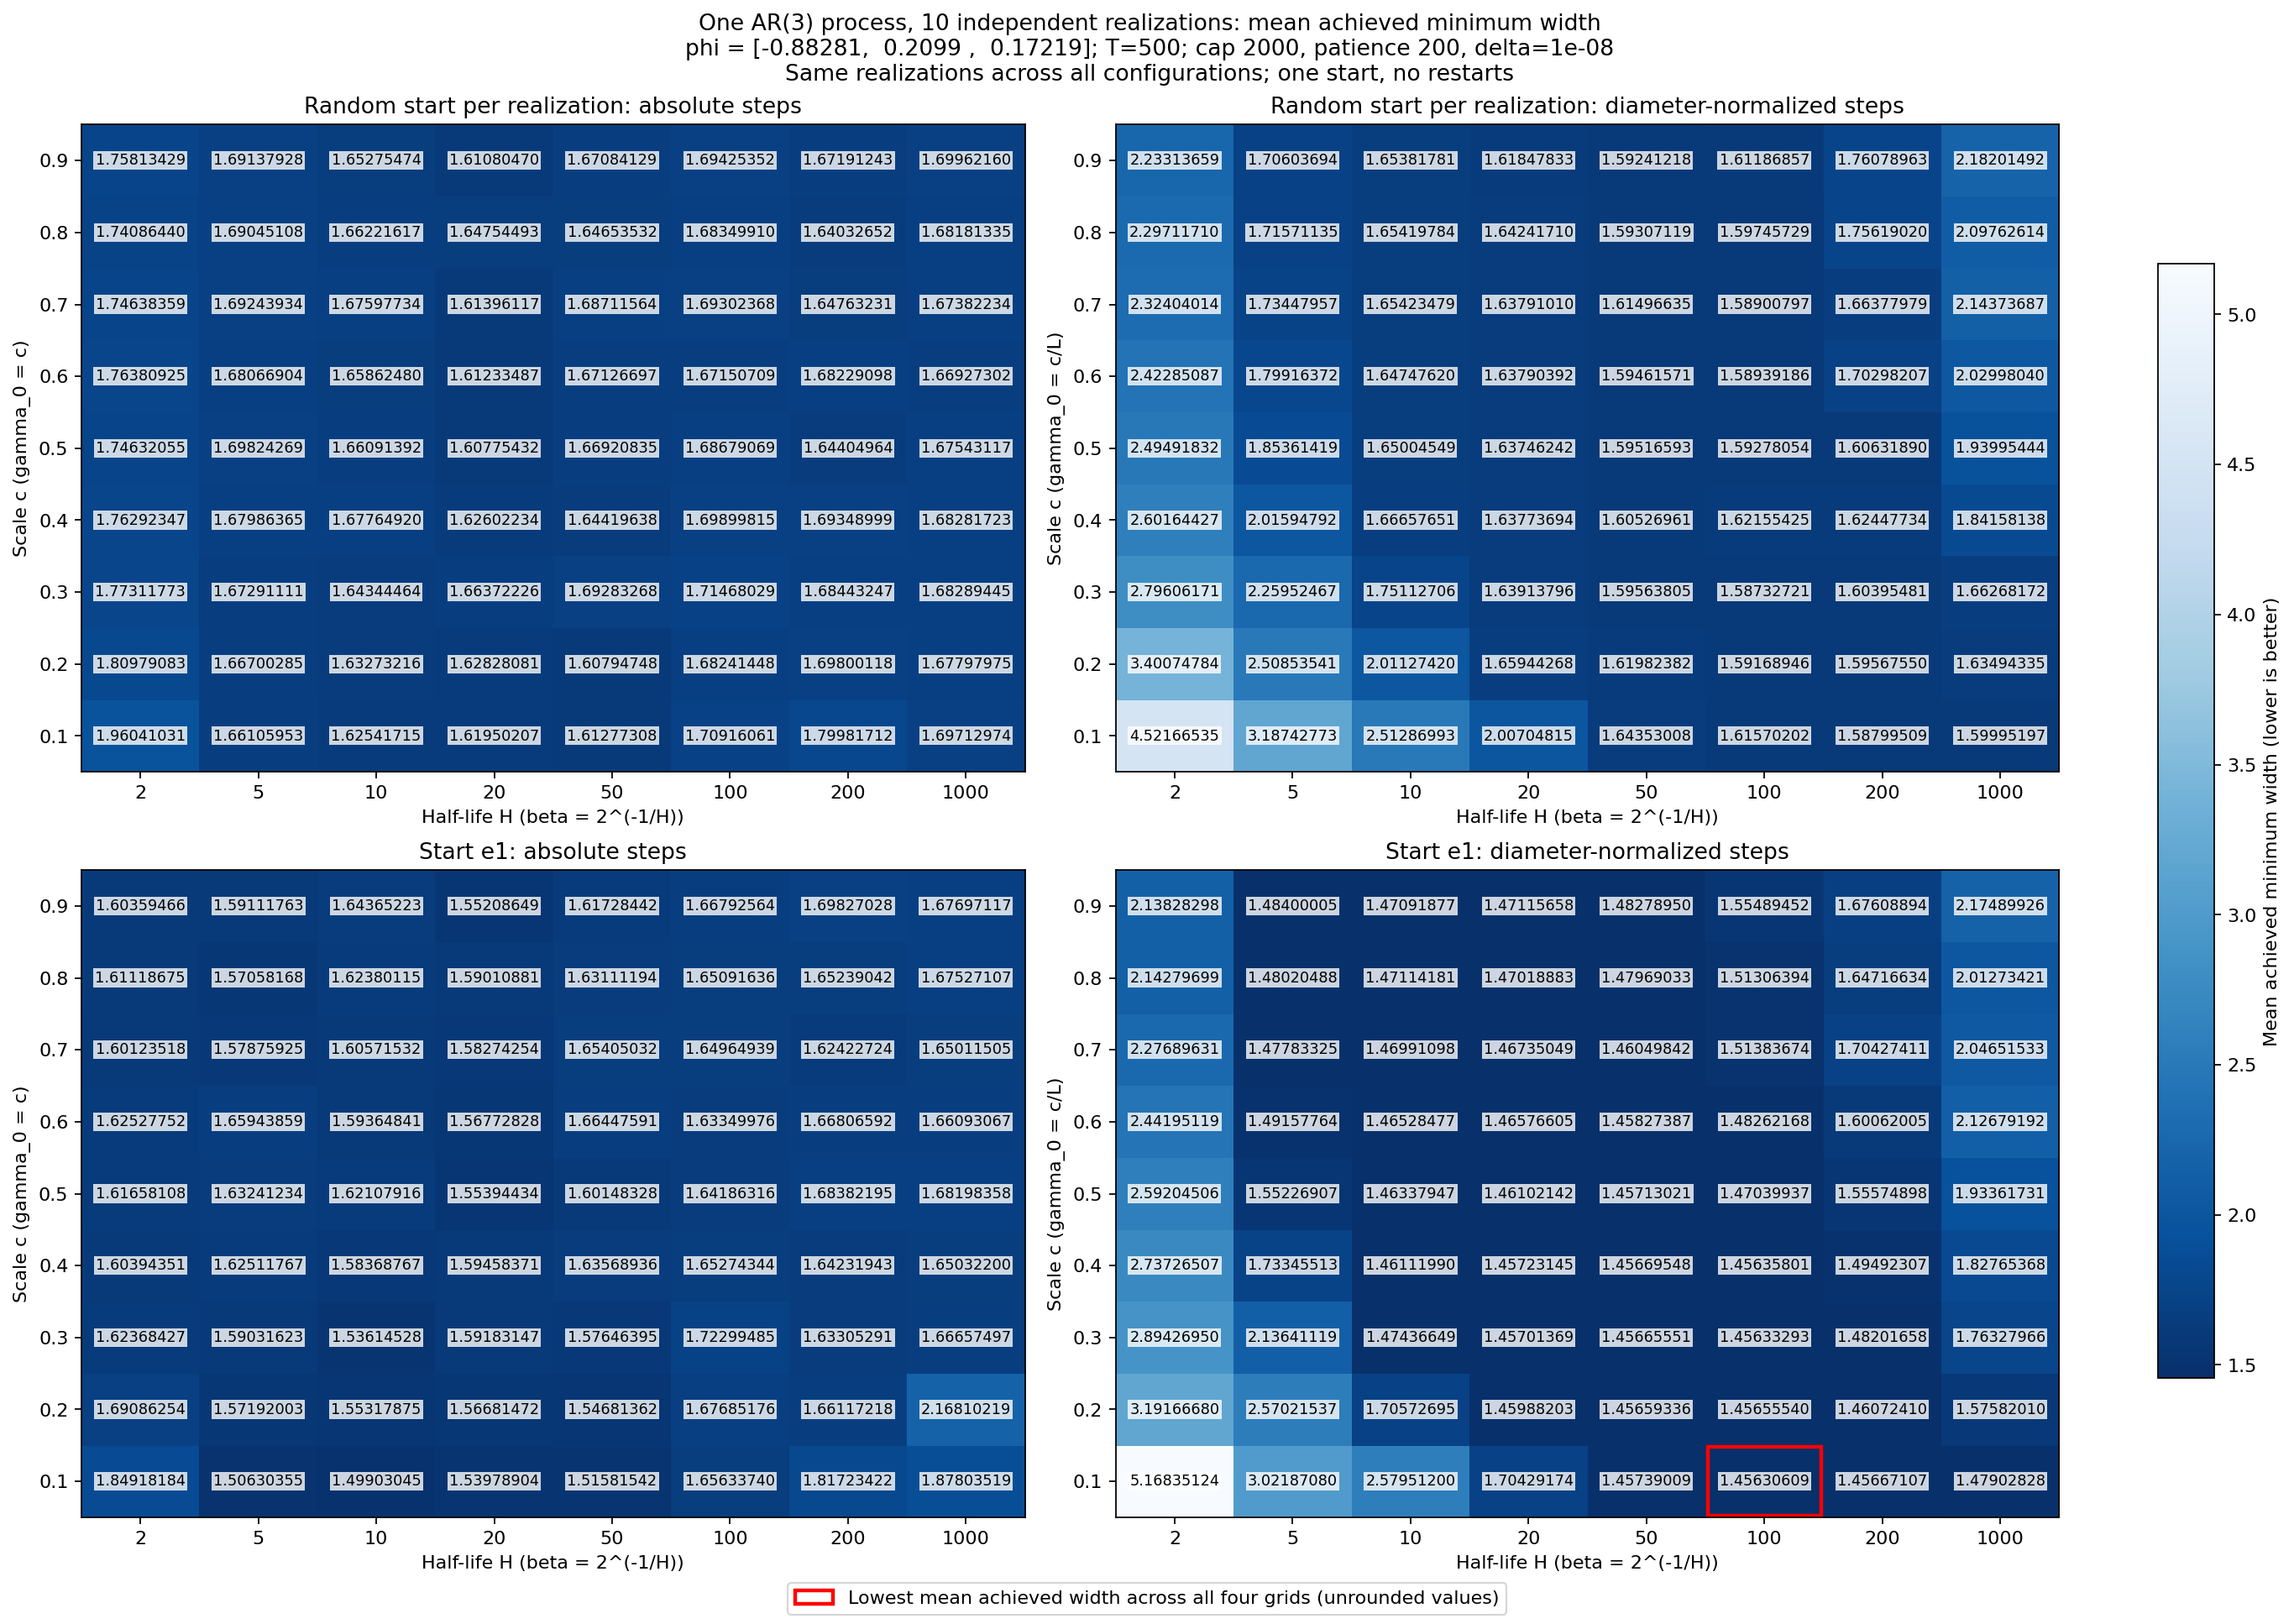

In [29]:
from matplotlib.patches import Patch, Rectangle
from Code.Code_AR_processes.ar_tools.plotting_functions import save_figure

single_ar_fig, single_ar_axes = plt.subplots(2, 2, figsize=(17, 12), constrained_layout=True)
single_ar_color_min = single_ar_summary["mean_achieved_width"].min()
single_ar_color_max = single_ar_summary["mean_achieved_width"].max()
single_ar_matrices = {}
for single_ar_row, single_ar_start in enumerate(("random_per_realization", "e1")):
    for single_ar_col, single_ar_rule in enumerate(("absolute", "diameter_normalized")):
        single_ar_ax = single_ar_axes[single_ar_row, single_ar_col]
        single_ar_panel = single_ar_summary.loc[
            single_ar_summary["initialization"].eq(single_ar_start)
            & single_ar_summary["step_rule"].eq(single_ar_rule)
        ]
        single_ar_matrix = single_ar_panel.pivot(
            index="step_value", columns="half_life", values="mean_achieved_width",
        ).reindex(index=scale_grid, columns=half_life_grid)
        assert single_ar_matrix.notna().all().all()
        single_ar_matrices[(single_ar_start, single_ar_rule)] = single_ar_matrix
        single_ar_image = single_ar_ax.imshow(
            single_ar_matrix.to_numpy(), origin="lower", aspect="auto", cmap="Blues_r",
            vmin=single_ar_color_min, vmax=single_ar_color_max,
        )
        for single_ar_i in range(len(scale_grid)):
            for single_ar_j in range(len(half_life_grid)):
                single_ar_value = single_ar_matrix.iloc[single_ar_i, single_ar_j]
                single_ar_ax.text(
                    single_ar_j, single_ar_i, f"{single_ar_value:.8f}",
                    ha="center", va="center", fontsize=8, color="black",
                    bbox={"facecolor": "white", "alpha": .8, "edgecolor": "none", "pad": 1},
                )
                if single_ar_value == single_ar_lowest_mean:
                    single_ar_ax.add_patch(Rectangle(
                        (single_ar_j-.48, single_ar_i-.48), .96, .96,
                        fill=False, edgecolor="red", linewidth=2,
                    ))
        single_ar_start_label = "Random start per realization" if single_ar_start == "random_per_realization" else "Start e1"
        single_ar_rule_label = "absolute steps" if single_ar_rule == "absolute" else "diameter-normalized steps"
        single_ar_ax.set(
            title=f"{single_ar_start_label}: {single_ar_rule_label}",
            xticks=np.arange(len(half_life_grid)), xticklabels=[f"{h:g}" for h in half_life_grid],
            yticks=np.arange(len(scale_grid)), yticklabels=[f"{c:g}" for c in scale_grid],
            xlabel="Half-life H (beta = 2^(-1/H))",
            ylabel="Scale c (gamma_0 = c)" if single_ar_rule == "absolute" else "Scale c (gamma_0 = c/L)",
        )
single_ar_phi_label = np.array2string(single_ar_phi, precision=5, separator=", ")
single_ar_fig.suptitle(
    f"One AR(3) process, {single_ar_realizations} independent realizations: mean achieved minimum width\n"
    f"phi = {single_ar_phi_label}; T={T}; cap {max_iterations}, patience {patience}, delta={delta:g}\n"
    "Same realizations across all configurations; one start, no restarts",
)
single_ar_fig.colorbar(
    single_ar_image, ax=single_ar_axes.ravel().tolist(), shrink=.8,
    label="Mean achieved minimum width (lower is better)",
)
single_ar_fig.legend(handles=[Patch(
    fill=False, edgecolor="red", linewidth=2,
    label="Lowest mean achieved width across all four grids (unrounded values)",
)], loc="outside lower center")
single_ar_figure_stem = f"14_single_ar_{single_ar_realizations}_realizations_mean_achieved_width_2x2"
save_figure(single_ar_fig, single_ar_figure_stem,
            pdf_directory=SINGLE_AR_PDF_DIR, image_directory=SINGLE_AR_IMAGE_DIR)
plt.show()
plt.close(single_ar_fig)


## 7. Process-level wins from 100 processes x 100 realizations

For each of 100 Jones-sampled causal AR(3) coefficient vectors, generate 100 independent innovation paths. All configurations and all four start/step variants use the same paths. Draw 100 random starting directions once; reuse direction r for realization r of every process and every random-start configuration. Coefficient draws, innovations and starting directions have separate seeded streams. The e1 variants always start at e1. [Sampler](../ar_tools/functions.py), [paired fixed-process runner](../ar_tools/tuning.py).

For each process and configuration, first average the achieved minimum widths across all 100 realizations. Compare these unrounded means across all four grids together. Every configuration within `hierarchical_mean_win_tolerance=1e-8` of that process's lowest mean receives +1. The final matrix cells show process-win counts from 0 to 100. Co-winners receive full points, so total credits may exceed 100. This counts process-level wins; it does not select by the overall average across all 10,000 realizations.

Red outlines mark every tied overall leader by final count. Light grey outlines mark every tied positive leader within each panel, using the same global-contest counts; grey is inset when red also applies. Entirely zero panels are labelled and receive no grey outlines. No MAE or maximum-iteration annotations are displayed.

Run only the shared imports/settings cells, then this section; earlier experiments are not required. Both experiment sizes are editable below. Defaults use 100 x 100 x 288 = 2,880,000 descents. Only process-level means and seed/start metadata are retained after each process, keeping memory bounded. The final figure is displayed and saved as PDF/PNG; no tables, raw fit files or extra figures are exported. This section is intentionally left unexecuted.


In [33]:
# Run the shared imports/settings cells, then Section 7 independently.
hierarchical_number_of_processes = 10
hierarchical_realizations_per_process = 10
hierarchical_coefficient_seed = 20261029
hierarchical_innovation_seed = 20261030
hierarchical_direction_seed = 20261031
hierarchical_mean_win_tolerance = 1e-8  # Applied to per-process means, after averaging.
hierarchical_n_jobs = 4  # Parallel realization workers within one process.


In [34]:
from Code.Code_AR_processes.ar_tools.functions import jones_ar_coefficients
tuning_tools = importlib.reload(tuning_tools)

for hierarchical_value, hierarchical_name in (
    (hierarchical_number_of_processes, "number of processes"),
    (hierarchical_realizations_per_process, "realizations per process"),
    (hierarchical_n_jobs, "workers"),
):
    if (isinstance(hierarchical_value, (bool, np.bool_))
            or not isinstance(hierarchical_value, (int, np.integer)) or hierarchical_value < 1):
        raise ValueError(f"The {hierarchical_name} must be a positive integer.")
if (not np.isfinite(hierarchical_mean_win_tolerance) or hierarchical_mean_win_tolerance < 0):
    raise ValueError("The mean-width tolerance must be finite and nonnegative.")

# Draw this bank once. Row r is reused for realization r of EVERY process.
hierarchical_start_bank = np.random.default_rng(hierarchical_direction_seed).normal(
    size=(hierarchical_realizations_per_process, embedding_dimension),
)
hierarchical_start_bank /= np.linalg.norm(hierarchical_start_bank, axis=1, keepdims=True)
hierarchical_e1 = np.zeros(embedding_dimension)
hierarchical_e1[0] = 1.
hierarchical_start_columns = [f"initial_u_{j}" for j in range(embedding_dimension)]

# Each process receives distinct coefficient and innovation streams.
# The fixed-process runner then spawns one innovation seed per realization.
hierarchical_coefficient_streams = np.random.SeedSequence(hierarchical_coefficient_seed).spawn(
    hierarchical_number_of_processes,
)
hierarchical_innovation_streams = np.random.SeedSequence(hierarchical_innovation_seed).spawn(
    hierarchical_number_of_processes,
)
hierarchical_models = pd.DataFrame([
    {
        "model_id": index + 1,
        "coefficient_seed": int(coefficient_stream.generate_state(1, dtype=np.uint64)[0]),
        "innovation_root_seed": int(innovation_stream.generate_state(1, dtype=np.uint64)[0]),
    }
    for index, (coefficient_stream, innovation_stream) in enumerate(zip(
        hierarchical_coefficient_streams, hierarchical_innovation_streams,
    ))
])
hierarchical_coefficients = np.stack([
    jones_ar_coefficients(p, rng=int(seed)) for seed in hierarchical_models["coefficient_seed"]
])
for hierarchical_j in range(p):
    hierarchical_models[f"phi_{hierarchical_j+1}"] = hierarchical_coefficients[:, hierarchical_j]
assert hierarchical_models["coefficient_seed"].is_unique
assert hierarchical_models["innovation_root_seed"].is_unique
assert np.unique(hierarchical_coefficients, axis=0).shape[0] == hierarchical_number_of_processes
hierarchical_grid_size = len(scale_grid) * len(half_life_grid)
hierarchical_total_descents = (
    hierarchical_number_of_processes * hierarchical_realizations_per_process * 4 * hierarchical_grid_size
)
hierarchical_configuration = {
    "experiment": "process_wins_from_mean_achieved_width", "processes": hierarchical_number_of_processes,
    "realizations_per_process": hierarchical_realizations_per_process,
    "coefficient_seed": hierarchical_coefficient_seed, "innovation_seed": hierarchical_innovation_seed,
    "direction_seed": hierarchical_direction_seed, "start_bank": hierarchical_start_bank.tolist(),
    "random_starts": "same_realization_index_reused_across_all_processes",
    "T": int(T), "p": int(p), "burnin": int(burnin), "optimizer_seed": int(optimizer_seed),
    "scale_grid": scale_grid.tolist(), "half_life_grid": half_life_grid.tolist(),
    "beta_grid": np.exp2(-1. / half_life_grid).tolist(),
    "iterations": int(max_iterations), "patience": int(patience), "delta": float(delta),
    "improvement_tolerance": float(improvement_tolerance),
    "mean_win_tolerance": float(hierarchical_mean_win_tolerance),
    "starts": 1, "stationarity_check": False, "max_restarts": 0,
    "source_sha256": hashlib.sha256(b"".join(
        (AR_CODE_DIR / "ar_tools" / name).read_bytes()
        for name in ("functions.py", "innovations.py", "descent.py", "tuning.py")
    )).hexdigest(),
}
hierarchical_run_id = hashlib.sha256(repr(sorted(hierarchical_configuration.items())).encode()).hexdigest()[:16]
HIERARCHICAL_PDF_DIR = OUTPUT_ROOT / "pdfs" / EXPERIMENT_NAME / f"hierarchical_process_wins_{hierarchical_run_id}"
HIERARCHICAL_IMAGE_DIR = OUTPUT_ROOT / "images" / EXPERIMENT_NAME / f"hierarchical_process_wins_{hierarchical_run_id}"
for hierarchical_directory in (HIERARCHICAL_PDF_DIR, HIERARCHICAL_IMAGE_DIR):
    hierarchical_directory.mkdir(parents=True, exist_ok=True)


In [35]:
def hierarchical_tune_one_process(model_id, phi, innovation_root_seed):
    """Average all realizations first, then award process-level co-winner credits."""
    frames = []
    reference_cases = None
    pairing_columns = [
        "replication", "T", "process_seed", "phi_1", "phi_2", "phi_3",
        "population_minimum_width", "empirical_true_direction_width",
    ]
    for initialization, directions in (
        ("random_shared_bank", hierarchical_start_bank), ("e1", hierarchical_e1),
    ):
        for step_rule in ("absolute", "diameter_normalized"):
            experiment = tuning_tools.tune_fixed_ar_realizations(
                phi, T, directions, scale_grid, half_life_grid,
                replications=hierarchical_realizations_per_process,
                process_seed=innovation_root_seed, burnin=burnin,
                iterations=max_iterations, patience=patience,
                improvement_tolerance=improvement_tolerance, delta=delta,
                optimizer_seed=optimizer_seed, step_rule=step_rule,
                stationarity_check=False, max_restarts=0, coefficient_diagnostics=False,
                n_jobs=hierarchical_n_jobs, progress=False, summarize=False,
            )
            cases = pd.DataFrame(experiment["cases"]).sort_values("replication").reset_index(drop=True)
            assert len(cases) == hierarchical_realizations_per_process
            assert cases["process_seed"].is_unique
            if reference_cases is None:
                reference_cases = cases.copy()
            pd.testing.assert_frame_equal(cases[pairing_columns], reference_cases[pairing_columns], check_exact=True)
            expected_starts = (hierarchical_start_bank if initialization == "random_shared_bank"
                               else np.tile(hierarchical_e1, (hierarchical_realizations_per_process, 1)))
            np.testing.assert_allclose(cases[hierarchical_start_columns], expected_starts, atol=1e-15, rtol=0)
            runs = pd.DataFrame(experiment["results"]).assign(initialization=initialization)
            assert len(runs) == hierarchical_realizations_per_process * hierarchical_grid_size
            assert not runs.duplicated(["candidate_id", "replication"]).any()
            assert np.isfinite(runs["minimum_width"]).all()  # Do not silently omit failed runs.
            assert runs["selected_start"].eq(1).all()
            assert runs["total_evaluations"].between(1, max_iterations).all()
            np.testing.assert_array_equal(runs[["phi_1", "phi_2", "phi_3"]], np.tile(phi, (len(runs), 1)))
            np.testing.assert_array_equal(
                runs[hierarchical_start_columns].to_numpy(),
                cases.set_index("replication").loc[runs["replication"], hierarchical_start_columns].to_numpy(),
            )
            frames.append(runs)
    all_runs = pd.concat(frames, ignore_index=True)
    means = all_runs.groupby(
        ["initialization", "step_rule", "candidate_id", "step_value", "half_life", "beta"], as_index=False,
    ).agg(mean_achieved_width=("minimum_width", "mean"), realization_count=("replication", "size"))
    assert len(means) == 4 * hierarchical_grid_size
    assert means["realization_count"].eq(hierarchical_realizations_per_process).all()
    process_best = means["mean_achieved_width"].min()
    means = means.assign(
        model_id=model_id, process_best_mean=process_best,
        process_win=means["mean_achieved_width"].le(process_best + hierarchical_mean_win_tolerance),
    )
    # Retain small summaries and seed/start records, rather than all raw descents.
    seed_records = reference_cases[pairing_columns + hierarchical_start_columns].assign(model_id=model_id)
    return means, seed_records


with capture_output():
    hierarchical_mean_frames = []
    hierarchical_seed_frames = []
    for hierarchical_model_index, hierarchical_model in hierarchical_models.iterrows():
        hierarchical_means, hierarchical_seeds = hierarchical_tune_one_process(
            int(hierarchical_model["model_id"]), hierarchical_coefficients[hierarchical_model_index],
            int(hierarchical_models.loc[hierarchical_model_index, "innovation_root_seed"]),
        )
        hierarchical_mean_frames.append(hierarchical_means)
        hierarchical_seed_frames.append(hierarchical_seeds)
    hierarchical_process_means = pd.concat(hierarchical_mean_frames, ignore_index=True)
    hierarchical_realization_metadata = pd.concat(hierarchical_seed_frames, ignore_index=True)
    assert hierarchical_realization_metadata["process_seed"].is_unique
    assert not hierarchical_process_means.duplicated(["model_id", "initialization", "candidate_id"]).any()
    hierarchical_ranking = hierarchical_process_means.groupby(
        ["initialization", "step_rule", "candidate_id", "step_value", "half_life", "beta"], as_index=False,
    ).agg(process_wins=("process_win", "sum"), process_count=("model_id", "nunique"))
    hierarchical_ranking["process_wins"] = hierarchical_ranking["process_wins"].astype(int)
    hierarchical_ranking = hierarchical_ranking.sort_values(
        ["process_wins", "initialization", "step_rule", "step_value", "half_life"],
        ascending=[False, True, True, True, True],
    ).reset_index(drop=True)
    assert hierarchical_ranking["process_count"].eq(hierarchical_number_of_processes).all()
    assert hierarchical_ranking["process_wins"].between(0, hierarchical_number_of_processes).all()
    assert hierarchical_ranking["process_wins"].sum() == hierarchical_process_means["process_win"].sum()
    assert hierarchical_process_means.groupby("model_id")["process_win"].any().all()
    hierarchical_best_count = int(hierarchical_ranking["process_wins"].max())
    hierarchical_leaders = hierarchical_ranking.loc[
        hierarchical_ranking["process_wins"].eq(hierarchical_best_count)
    ].copy()


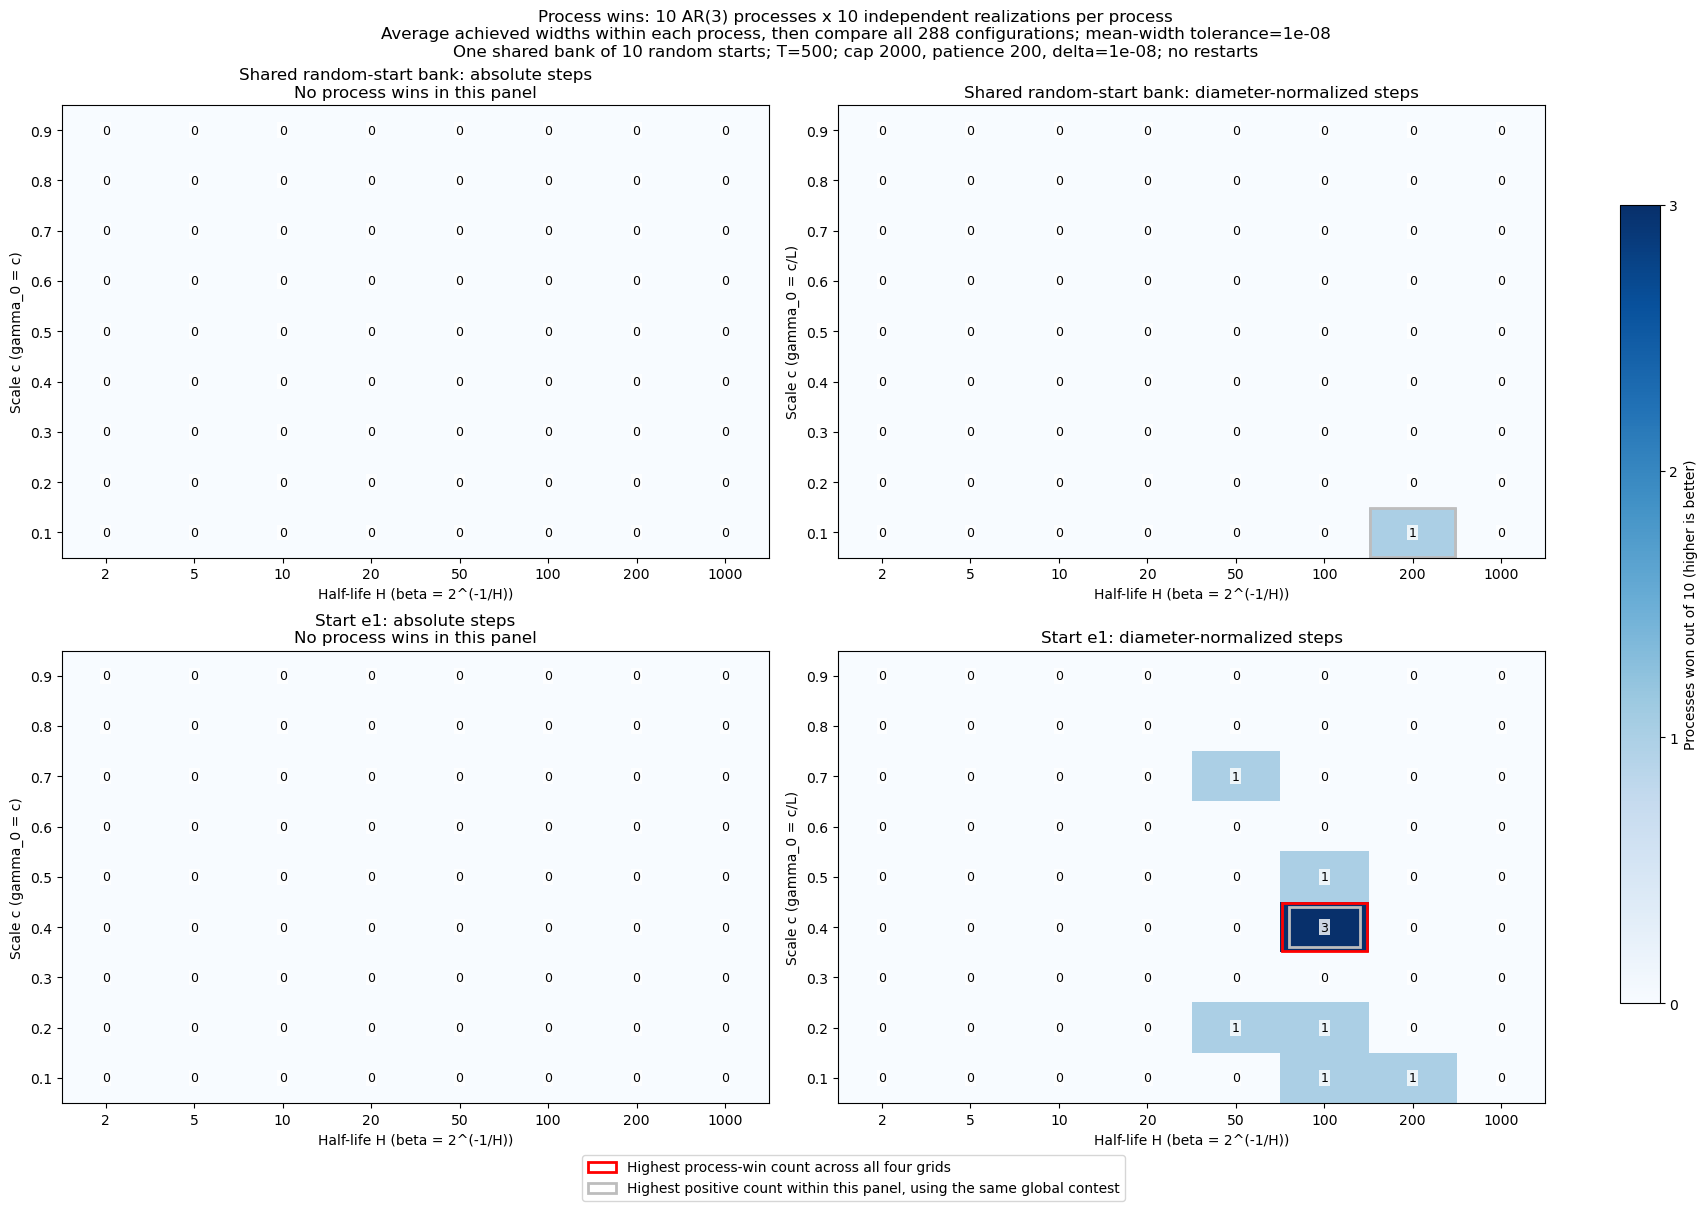

In [36]:
from matplotlib.patches import Patch, Rectangle
from Code.Code_AR_processes.ar_tools.plotting_functions import save_figure

hierarchical_fig, hierarchical_axes = plt.subplots(2, 2, figsize=(17, 12), constrained_layout=True)
hierarchical_color_max = max(1, hierarchical_best_count)
hierarchical_grey = "#bdbdbd"
hierarchical_matrices = {}
for hierarchical_row, hierarchical_start in enumerate(("random_shared_bank", "e1")):
    for hierarchical_col, hierarchical_rule in enumerate(("absolute", "diameter_normalized")):
        hierarchical_ax = hierarchical_axes[hierarchical_row, hierarchical_col]
        hierarchical_panel = hierarchical_ranking.loc[
            hierarchical_ranking["initialization"].eq(hierarchical_start)
            & hierarchical_ranking["step_rule"].eq(hierarchical_rule)
        ]
        hierarchical_matrix = hierarchical_panel.pivot(
            index="step_value", columns="half_life", values="process_wins",
        ).reindex(index=scale_grid, columns=half_life_grid)
        assert hierarchical_matrix.notna().all().all()
        hierarchical_matrices[(hierarchical_start, hierarchical_rule)] = hierarchical_matrix
        hierarchical_panel_best = int(hierarchical_panel["process_wins"].max())
        hierarchical_image = hierarchical_ax.imshow(
            hierarchical_matrix.to_numpy(), origin="lower", aspect="auto", cmap="Blues",
            vmin=0, vmax=hierarchical_color_max,
        )
        for hierarchical_i in range(len(scale_grid)):
            for hierarchical_j in range(len(half_life_grid)):
                hierarchical_count = int(hierarchical_matrix.iloc[hierarchical_i, hierarchical_j])
                hierarchical_ax.text(
                    hierarchical_j, hierarchical_i, str(hierarchical_count),
                    ha="center", va="center", fontsize=9, color="black",
                    bbox={"facecolor":"white", "alpha":.8, "edgecolor":"none", "pad":1},
                )
                if hierarchical_panel_best > 0 and hierarchical_count == hierarchical_panel_best:
                    hierarchical_extent = .40 if hierarchical_count == hierarchical_best_count else .48
                    hierarchical_ax.add_patch(Rectangle(
                        (hierarchical_j-hierarchical_extent, hierarchical_i-hierarchical_extent),
                        2*hierarchical_extent, 2*hierarchical_extent,
                        fill=False, edgecolor=hierarchical_grey, linewidth=2,
                    ))
                if hierarchical_count == hierarchical_best_count:
                    hierarchical_ax.add_patch(Rectangle(
                        (hierarchical_j-.48, hierarchical_i-.48), .96, .96,
                        fill=False, edgecolor="red", linewidth=2,
                    ))
        hierarchical_start_label = "Shared random-start bank" if hierarchical_start == "random_shared_bank" else "Start e1"
        hierarchical_rule_label = "absolute steps" if hierarchical_rule == "absolute" else "diameter-normalized steps"
        hierarchical_panel_title = f"{hierarchical_start_label}: {hierarchical_rule_label}"
        if hierarchical_panel_best == 0:
            hierarchical_panel_title += "\nNo process wins in this panel"
        hierarchical_ax.set(
            title=hierarchical_panel_title,
            xticks=np.arange(len(half_life_grid)), xticklabels=[f"{h:g}" for h in half_life_grid],
            yticks=np.arange(len(scale_grid)), yticklabels=[f"{c:g}" for c in scale_grid],
            xlabel="Half-life H (beta = 2^(-1/H))",
            ylabel="Scale c (gamma_0 = c)" if hierarchical_rule == "absolute" else "Scale c (gamma_0 = c/L)",
        )
hierarchical_fig.suptitle(
    f"Process wins: {hierarchical_number_of_processes} AR(3) processes x "
    f"{hierarchical_realizations_per_process} independent realizations per process\n"
    f"Average achieved widths within each process, then compare all {4*hierarchical_grid_size} configurations; "
    f"mean-width tolerance={hierarchical_mean_win_tolerance:g}\n"
    f"One shared bank of {hierarchical_realizations_per_process} random starts; T={T}; "
    f"cap {max_iterations}, patience {patience}, delta={delta:g}; no restarts",
)
hierarchical_colorbar = hierarchical_fig.colorbar(
    hierarchical_image, ax=hierarchical_axes.ravel().tolist(), shrink=.8,
    label=f"Processes won out of {hierarchical_number_of_processes} (higher is better)",
)
hierarchical_colorbar.set_ticks(np.unique(np.linspace(
    0, hierarchical_color_max, min(hierarchical_color_max+1, 8), dtype=int,
)))
hierarchical_fig.legend(handles=[
    Patch(fill=False, edgecolor="red", linewidth=2, label="Highest process-win count across all four grids"),
    Patch(fill=False, edgecolor=hierarchical_grey, linewidth=2,
          label="Highest positive count within this panel, using the same global contest"),
], loc="outside lower center", ncol=1)
hierarchical_figure_stem = (
    f"15_hierarchical_{hierarchical_number_of_processes}_processes_"
    f"{hierarchical_realizations_per_process}_realizations_process_win_counts_2x2"
)
save_figure(hierarchical_fig, hierarchical_figure_stem,
            pdf_directory=HIERARCHICAL_PDF_DIR, image_directory=HIERARCHICAL_IMAGE_DIR)
plt.show()
plt.close(hierarchical_fig)
